In [ ]:
import sys
import numpy as np
import pandas as pd

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy version: 2.1.3
Pandas version: 2.2.3


In [ ]:
import urllib.request
import json

url = "https://huggingface.co/api/datasets/McAuley-Lab/Amazon-Reviews-2023/tree/main/raw/review_categories"

with urllib.request.urlopen(url) as response:
    files = json.loads(response.read().decode())

print("Searching for the Video Games dataset...\n")

for file in files:
    if "Video_Games" in file["path"] or "Video Games" in file["path"]:
        print("File:", file["path"])
        print("Size:", round(file.get("size", 0) / (1024**2), 2), "MB")
        print()

Searching for the Video Games dataset...

File: raw/review_categories/Video_Games.jsonl
Size: 2558.66 MB



1. We are using the Amazon Reviews 2023 dataset for our Video Game Recommendation System. The dataset is hosted on Hugging Face and contains customer reviews of Amazon products.

2. We selected the Video Games category because our project focuses on recommending video games to users.

3. The original Video Games review file is approximately 2.56 GB

In [ ]:
import urllib.request
import json

url = "https://huggingface.co/api/datasets/McAuley-Lab/Amazon-Reviews-2023/tree/main/benchmark/0core/last_out"

with urllib.request.urlopen(url) as response:
    files = json.loads(response.read().decode())

print("Video Games benchmark files:\n")

for file in files:
    if "Video_Games" in file["path"]:
        print("File:", file["path"])
        print("Size:", round(file.get("size", 0) / (1024**2), 2), "MB")

Video Games benchmark files:

File: benchmark/0core/last_out/Video_Games.test.csv
Size: 153.03 MB
File: benchmark/0core/last_out/Video_Games.train.csv
Size: 57.8 MB
File: benchmark/0core/last_out/Video_Games.valid.csv
Size: 41.14 MB


The Amazon Reviews 2023 dataset provides prepared training, validation, and test files for the Video Games category.



*   Training data: Video_Games.train.csv
*  Validation data: Video_Games.valid.csv


*   Test data: Video_Games.test.csv

We will use the training data to build our recommendation methods, the validation data to tune and compare them during development, and the test data for final evaluation




In [ ]:
import pandas as pd

train_url = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/resolve/main/"
    "benchmark/0core/last_out/Video_Games.train.csv"
)

train_df = pd.read_csv(train_url)

print("Dataset loaded successfully!")
print("Shape:", train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst five rows:")
display(train_df.head())

print("\nMissing values:")
print(train_df.isnull().sum())

Dataset loaded successfully!
Shape: (1045048, 4)

Column names:
['user_id', 'parent_asin', 'rating', 'timestamp']

First five rows:


,user_id,parent_asin,rating,timestamp
0,AG6BAEKWLCWH2TW3KKLVK773YF6A,B0B36HX334,1.0,1523313903402
1,AG6BAEKWLCWH2TW3KKLVK773YF6A,B001AW156U,4.0,1523314072900
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1611459666223
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1613701986538
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1613702112995



Missing values:
user_id        0
parent_asin    0
rating         0
timestamp      0
dtype: int64


In [ ]:
# STEP 6: Basic dataset exploration

num_interactions = len(train_df)
num_users = train_df["user_id"].nunique()
num_games = train_df["parent_asin"].nunique()

print("========== DATASET OVERVIEW ==========")
print(f"Total interactions: {num_interactions:,}")
print(f"Unique users:      {num_users:,}")
print(f"Unique games:      {num_games:,}")

# Ratings distribution
print("\n========== RATINGS DISTRIBUTION ==========")
print(train_df["rating"].value_counts().sort_index())

# Interactions per user
user_counts = train_df.groupby("user_id")["parent_asin"].count()

print("\n========== USER ACTIVITY ==========")
print(f"Average ratings per user: {user_counts.mean():.2f}")
print(f"Median ratings per user:  {user_counts.median():.0f}")
print(f"Users with only 1 rating: {(user_counts == 1).sum():,}")

# Interactions per game
game_counts = train_df.groupby("parent_asin")["user_id"].count()

print("\n========== GAME ACTIVITY ==========")
print(f"Average ratings per game: {game_counts.mean():.2f}")
print(f"Median ratings per game:  {game_counts.median():.0f}")
print(f"Games with only 1 rating: {(game_counts == 1).sum():,}")

# Matrix sparsity
total_possible = num_users * num_games
sparsity = 1 - (num_interactions / total_possible)

print("\n========== INTERACTION MATRIX ==========")
print(f"Possible user-game pairs: {total_possible:,}")
print(f"Observed interactions:    {num_interactions:,}")
print(f"Matrix sparsity:          {sparsity:.6%}")

========== DATASET OVERVIEW ==========
Total interactions: 1,045,048
Unique users:      329,719
Unique games:      83,630

========== RATINGS DISTRIBUTION ==========
rating
1.0     75854
2.0     48783
3.0     89692
4.0    171316
5.0    659403
Name: count, dtype: int64

========== USER ACTIVITY ==========
Average ratings per user: 3.17
Median ratings per user:  2
Users with only 1 rating: 147,504

========== GAME ACTIVITY ==========
Average ratings per game: 12.50
Median ratings per game:  2
Games with only 1 rating: 30,531

========== INTERACTION MATRIX ==========
Possible user-game pairs: 27,574,399,970
Observed interactions:    1,045,048
Matrix sparsity:          99.996210%


1. After calculating the basic statistics, we visualize the dataset to understand the distribution of ratings and user activity.

2. The ratings distribution shows how frequently users give ratings from 1 to 5. The user activity distribution shows how many ratings individual users have submitted.

3. These visualizations help us identify rating imbalances and users with limited interaction histories. Such characteristics are important when designing and evaluating recommendation algorithms, particularly for cold-start scenarios.

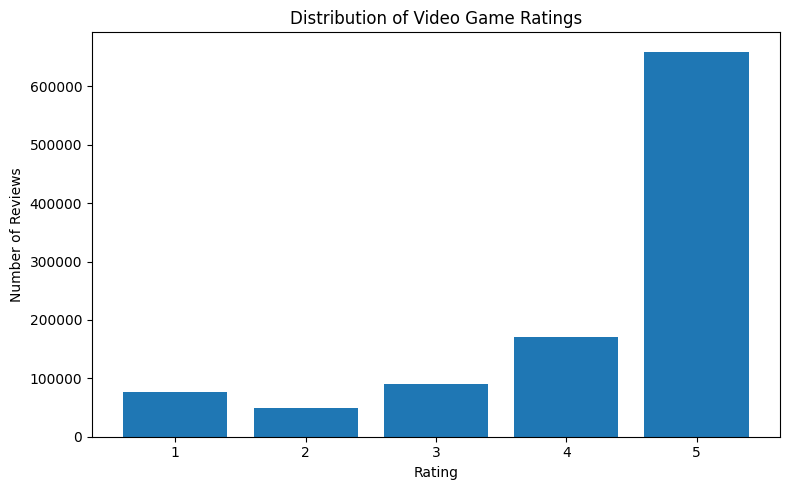

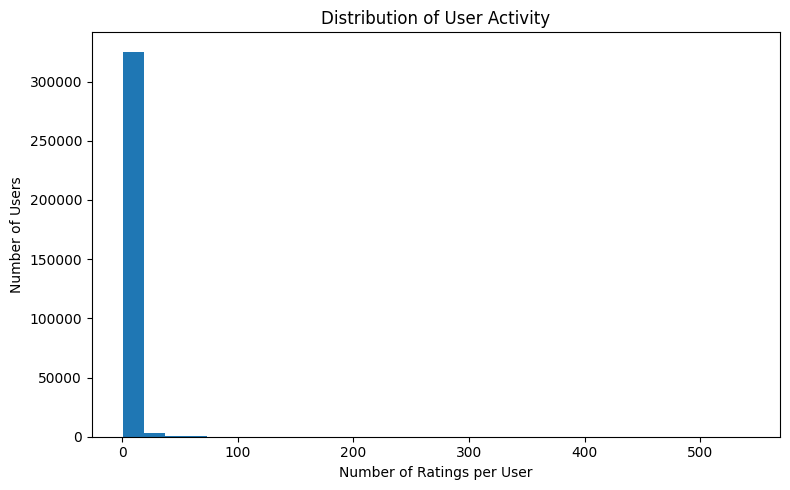

In [ ]:
import matplotlib.pyplot as plt

# Plot 1: Rating distribution
rating_counts = train_df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values)
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Video Game Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()


# Plot 2: User activity distribution
user_counts = train_df.groupby("user_id")["parent_asin"].count()

plt.figure(figsize=(8, 5))
plt.hist(user_counts, bins=30)
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")
plt.title("Distribution of User Activity")
plt.tight_layout()
plt.show()

Graph 1: Your dataset has many more five-star ratings than one-star ratings. This indicates that the rating distribution is imbalanced.

Graph 2: Many users have submitted only a small number of ratings. This means that personalizing recommendations from interaction history alone may be difficult for a substantial portion of users.

In [ ]:
# Check for repeated user-game pairs

duplicate_mask = train_df.duplicated(
    subset=["user_id", "parent_asin"],
    keep=False
)

duplicate_rows = train_df.loc[duplicate_mask]

print("Total rows:", len(train_df))
print("Rows involved in repeated user-game pairs:", len(duplicate_rows))

print(
    "Number of repeated user-game pairs:",
    train_df.duplicated(
        subset=["user_id", "parent_asin"]
    ).sum()
)

print("\nExample repeated interactions:")
display(duplicate_rows.head(10))

Total rows: 1045048
Rows involved in repeated user-game pairs: 0
Number of repeated user-game pairs: 0

Example repeated interactions:


,user_id,parent_asin,rating,timestamp


We checked the training dataset for repeated combinations of user_id and parent_asin.

The dataset contains 1,045,048 interactions, and no repeated user–game pairs were found.

This indicates that each user–game combination occurs only once in the training dataset. Therefore, no duplicate-pair removal is required at this stage.



In [ ]:
# Load validation and test datasets

valid_url = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/resolve/main/"
    "benchmark/0core/last_out/Video_Games.valid.csv"
)

test_url = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/resolve/main/"
    "benchmark/0core/last_out/Video_Games.test.csv"
)

valid_df = pd.read_csv(valid_url)
test_df = pd.read_csv(test_url)

print("Training shape:", train_df.shape)
print("Validation shape:", valid_df.shape)
print("Test shape:", test_df.shape)

Training shape: (1045048, 4)
Validation shape: (743796, 4)
Test shape: (2766656, 4)


We load the validation and test datasets separately from the training dataset.

The validation dataset will be used during model development, while the test dataset will be reserved for final evaluation.

In [ ]:
# Collect unique users and games from each dataset

train_users = set(train_df["user_id"].unique())
valid_users = set(valid_df["user_id"].unique())
test_users = set(test_df["user_id"].unique())

train_games = set(train_df["parent_asin"].unique())
valid_games = set(valid_df["parent_asin"].unique())
test_games = set(test_df["parent_asin"].unique())


# Validation dataset analysis

print("========== VALIDATION COVERAGE ==========")

print("Total validation interactions:", len(valid_df))

print(
    "Interactions involving users unseen in training:",
    (~valid_df["user_id"].isin(train_users)).sum()
)

print(
    "Interactions involving games unseen in training:",
    (~valid_df["parent_asin"].isin(train_games)).sum()
)


# Test dataset analysis

print("\n========== TEST COVERAGE ==========")

print("Total test interactions:", len(test_df))

print(
    "Interactions involving users unseen in training:",
    (~test_df["user_id"].isin(train_users)).sum()
)

print(
    "Interactions involving games unseen in training:",
    (~test_df["parent_asin"].isin(train_games)).sum()
)

========== VALIDATION COVERAGE ==========
Total validation interactions: 743796
Interactions involving users unseen in training: 414077
Interactions involving games unseen in training: 25644

========== TEST COVERAGE ==========
Total test interactions: 2766656
Interactions involving users unseen in training: 2436937
Interactions involving games unseen in training: 121233


In [ ]:
# Calculate percentages of unseen users and games

validation_user_pct = (
    (~valid_df["user_id"].isin(train_users)).mean() * 100
)

validation_game_pct = (
    (~valid_df["parent_asin"].isin(train_games)).mean() * 100
)

test_user_pct = (
    (~test_df["user_id"].isin(train_users)).mean() * 100
)

test_game_pct = (
    (~test_df["parent_asin"].isin(train_games)).mean() * 100
)

print("VALIDATION SET")
print(f"Interactions involving unseen users: {validation_user_pct:.2f}%")
print(f"Interactions involving unseen games: {validation_game_pct:.2f}%")

print("\nTEST SET")
print(f"Interactions involving unseen users: {test_user_pct:.2f}%")
print(f"Interactions involving unseen games: {test_game_pct:.2f}%")

VALIDATION SET
Interactions involving unseen users: 55.67%
Interactions involving unseen games: 3.45%

TEST SET
Interactions involving unseen users: 88.08%
Interactions involving unseen games: 4.38%


The analysis shows that 55.67% of validation interactions and 88.08% of test interactions involve users who do not appear in the training dataset.

This indicates that new-user cold start is an important challenge in our dataset. A Matrix Factorization model trained only on the training interactions cannot learn personalized user factors for users who are completely absent from training.

The analysis also shows that 3.45% of validation interactions and 4.38% of test interactions involve games unseen during training. These interactions are relevant to new-game cold-start recommendation.

Semantic Recommendation and LLM-Based Recommendation may handle new games by using product metadata, such as titles, descriptions, and categories.



# Matrix Factorization

Imagine we have a user–game rating matrix:

| User | Minecraft | FIFA | Racing Game |
|---|---:|---:|---:|
| User A | 5 | 4 | ? |
| User B | 1 | ? | 5 |
| User C | ? | 5 | 2 |

The question mark represents a rating we haven't observed.

Matrix Factorization tries to learn hidden characteristics of users and games from existing ratings. For example, it might learn that a user enjoys racing games or that a game appeals to players who enjoy exploration.

It uses these learned representations to predict how a user might rate a game they haven't rated before.

In [ ]:
# Select the columns required for Matrix Factorization

mf_df = train_df[["user_id", "parent_asin", "rating"]].copy()

# Create numerical indices for users and games

user_ids = mf_df["user_id"].unique()
game_ids = mf_df["parent_asin"].unique()

user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
game_to_idx = {game_id: idx for idx, game_id in enumerate(game_ids)}

idx_to_user = {idx: user_id for user_id, idx in user_to_idx.items()}
idx_to_game = {idx: game_id for game_id, idx in game_to_idx.items()}

# Convert original identifiers to numerical indices

mf_df["user_idx"] = mf_df["user_id"].map(user_to_idx)
mf_df["game_idx"] = mf_df["parent_asin"].map(game_to_idx)

print("Matrix Factorization dataset prepared!")
print("Number of users:", len(user_to_idx))
print("Number of games:", len(game_to_idx))
print("Number of ratings:", len(mf_df))

display(mf_df.head())

Matrix Factorization dataset prepared!
Number of users: 329719
Number of games: 83630
Number of ratings: 1045048


,user_id,parent_asin,rating,user_idx,game_idx
0,AG6BAEKWLCWH2TW3KKLVK773YF6A,B0B36HX334,1.0,0,0
1,AG6BAEKWLCWH2TW3KKLVK773YF6A,B001AW156U,4.0,0,1
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1,2
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1,3
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1,4


The training dataset contains user identifiers, product identifiers, ratings, and timestamps. For our initial Matrix Factorization model, we require only the user identifiers, product identifiers, and ratings.

We will convert the user and product identifiers into integer indices because the model uses numerical indices to represent users and games internally.

The original identifiers will be retained in mappings so that predictions can later be associated with the correct users and games.

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
CUDA available: False


In [ ]:
import numpy as np
import pandas as pd

# Reproducible random split
rng = np.random.default_rng(42)

# Shuffle all available interactions
shuffled_indices = rng.permutation(len(mf_df))

# Use 80% for training and 20% for validation
split_point = int(0.80 * len(shuffled_indices))

train_indices = shuffled_indices[:split_point]
valid_indices = shuffled_indices[split_point:]

train_mf = mf_df.iloc[train_indices].copy()
valid_mf = mf_df.iloc[valid_indices].copy()

# Identify users and games present in the training set
known_users = set(train_mf["user_id"].unique())
known_games = set(train_mf["parent_asin"].unique())

# Keep validation rows only when both user and game are known
valid_mf = valid_mf[
    valid_mf["user_id"].isin(known_users)
    & valid_mf["parent_asin"].isin(known_games)
].copy()

# Rebuild mappings using training data only
train_user_ids = train_mf["user_id"].unique()
train_game_ids = train_mf["parent_asin"].unique()

user_to_idx = {
    user_id: idx for idx, user_id in enumerate(train_user_ids)
}

game_to_idx = {
    game_id: idx for idx, game_id in enumerate(train_game_ids)
}

# Map IDs to numerical indices
train_mf["user_idx"] = train_mf["user_id"].map(user_to_idx)
train_mf["game_idx"] = train_mf["parent_asin"].map(game_to_idx)

valid_mf["user_idx"] = valid_mf["user_id"].map(user_to_idx)
valid_mf["game_idx"] = valid_mf["parent_asin"].map(game_to_idx)

print("Training interactions:", len(train_mf))
print("Validation interactions:", len(valid_mf))
print("Users available for training:", len(user_to_idx))
print("Games available for training:", len(game_to_idx))
print("Training rating mean:", round(train_mf["rating"].mean(), 4))
print("Validation rating mean:", round(valid_mf["rating"].mean(), 4))
print("Validation rows remaining:", f"{len(valid_mf) / max(1, int(0.20 * len(mf_df))) * 100:.2f}% of the original validation split")

Training interactions: 836038
Validation interactions: 166993
Users available for training: 297146
Games available for training: 76961
Training rating mean: 4.2347
Validation rating mean: 4.2565
Validation rows remaining: 79.90% of the original validation split


Approximately 79.9% of the original validation interactions remain after filtering out interactions involving unseen users or games. That is expected because some users and games appear only once in the original dataset.

In [ ]:
import torch
import torch.nn as nn

# Use CPU because CUDA is unavailable
device = torch.device("cpu")

# Model configuration
NUM_USERS = len(user_to_idx)
NUM_GAMES = len(game_to_idx)
NUM_FACTORS = 32

# Define Matrix Factorization model
class MatrixFactorization(nn.Module):
    def __init__(self, num_users, num_games, num_factors=32):
        super().__init__()

        # Latent factor embeddings
        self.user_embedding = nn.Embedding(num_users, num_factors)
        self.game_embedding = nn.Embedding(num_games, num_factors)

        # User and game bias terms
        self.user_bias = nn.Embedding(num_users, 1)
        self.game_bias = nn.Embedding(num_games, 1)

        # Global average rating
        self.global_mean = nn.Parameter(torch.tensor(4.2347))

        # Initialize embeddings with small random values
        nn.init.normal_(self.user_embedding.weight, mean=0.0, std=0.05)
        nn.init.normal_(self.game_embedding.weight, mean=0.0, std=0.05)

        # Initialize biases to zero
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.game_bias.weight)

    def forward(self, user_idx, game_idx):
        user_factors = self.user_embedding(user_idx)
        game_factors = self.game_embedding(game_idx)

        interaction = (user_factors * game_factors).sum(dim=1)

        user_bias = self.user_bias(user_idx).squeeze()
        game_bias = self.game_bias(game_idx).squeeze()

        prediction = (
            self.global_mean
            + user_bias
            + game_bias
            + interaction
        )

        return prediction


# Create the model
model = MatrixFactorization(
    num_users=NUM_USERS,
    num_games=NUM_GAMES,
    num_factors=NUM_FACTORS
).to(device)

print(model)
print("\nDevice:", device)
print("Number of users:", NUM_USERS)
print("Number of games:", NUM_GAMES)
print("Latent factors:", NUM_FACTORS)

total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

print("Total trainable parameters:", f"{total_parameters:,}")

MatrixFactorization(
  (user_embedding): Embedding(297146, 32)
  (game_embedding): Embedding(76961, 32)
  (user_bias): Embedding(297146, 1)
  (game_bias): Embedding(76961, 1)
)

Device: cpu
Number of users: 297146
Number of games: 76961
Latent factors: 32
Total trainable parameters: 12,345,532


In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)

# Convert training data into tensors
train_users_tensor = torch.tensor(
    train_mf["user_idx"].to_numpy(),
    dtype=torch.long
)

train_games_tensor = torch.tensor(
    train_mf["game_idx"].to_numpy(),
    dtype=torch.long
)

train_ratings_tensor = torch.tensor(
    train_mf["rating"].to_numpy(),
    dtype=torch.float32
)

# Convert validation data into tensors
valid_users_tensor = torch.tensor(
    valid_mf["user_idx"].to_numpy(),
    dtype=torch.long
)

valid_games_tensor = torch.tensor(
    valid_mf["game_idx"].to_numpy(),
    dtype=torch.long
)

valid_ratings_tensor = torch.tensor(
    valid_mf["rating"].to_numpy(),
    dtype=torch.float32
)

# Create training batches
BATCH_SIZE = 4096

train_dataset = TensorDataset(
    train_users_tensor,
    train_games_tensor,
    train_ratings_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Optimizer and loss function
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.005
)

mse_loss = torch.nn.MSELoss()

print("Training batches:", len(train_loader))
print("Batch size:", BATCH_SIZE)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_ratings_tensor))
print("Optimizer: Adam")
print("Learning rate: 0.005")

Training batches: 205
Batch size: 4096
Training samples: 836038
Validation samples: 166993
Optimizer: Adam
Learning rate: 0.005


In this step, we train the Matrix Factorization model using the training dataset.

The model learns by comparing its predicted ratings with the actual ratings provided by users. We use Mean Squared Error (MSE) as the primary loss function and the Adam optimizer to update the model parameters.

L2 regularization is applied to the user and game latent factors to reduce overfitting. The training dataset is divided into batches so that the model can process the data efficiently on the available CPU.

After each epoch, the model is evaluated on the validation dataset. We calculate Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE) to measure rating prediction accuracy.

In [ ]:
import numpy as np

EPOCHS = 5
REGULARIZATION = 1e-5

history = []

for epoch in range(EPOCHS):
    model.train()

    total_squared_error = 0.0
    total_samples = 0

    for user_batch, game_batch, rating_batch in train_loader:

        # Forward pass
        predictions = model(user_batch, game_batch)

        # Prediction error
        prediction_loss = mse_loss(predictions, rating_batch)

        # L2 regularization on latent factor embeddings
        regularization_loss = REGULARIZATION * (
            model.user_embedding(user_batch).pow(2).sum(dim=1).mean()
            + model.game_embedding(game_batch).pow(2).sum(dim=1).mean()
        )

        loss = prediction_loss + regularization_loss

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Accumulate training squared error
        with torch.no_grad():
            total_squared_error += (
                (predictions - rating_batch).pow(2).sum().item()
            )
            total_samples += len(rating_batch)

    train_rmse = np.sqrt(total_squared_error / total_samples)

    # Evaluate on validation data
    model.eval()

    with torch.no_grad():
        valid_predictions = []

        for start in range(0, len(valid_ratings_tensor), 8192):
            end = start + 8192

            batch_predictions = model(
                valid_users_tensor[start:end],
                valid_games_tensor[start:end]
            )

            valid_predictions.append(batch_predictions)

        valid_predictions = torch.cat(valid_predictions)

        # Ratings are between 1 and 5; constrain predictions accordingly
        valid_predictions = torch.clamp(valid_predictions, 1.0, 5.0)

        validation_errors = valid_predictions - valid_ratings_tensor

        valid_rmse = torch.sqrt(
            torch.mean(validation_errors ** 2)
        ).item()

        valid_mae = torch.mean(
            torch.abs(validation_errors)
        ).item()

    history.append({
        "epoch": epoch + 1,
        "train_rmse": train_rmse,
        "validation_rmse": valid_rmse,
        "validation_mae": valid_mae
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Validation RMSE: {valid_rmse:.4f} | "
        f"Validation MAE: {valid_mae:.4f}"
    )

history_df = pd.DataFrame(history)

print("\nTraining completed.")
display(history_df)

Epoch 1/5 | Train RMSE: 1.1934 | Validation RMSE: 1.1307 | Validation MAE: 0.8688
Epoch 2/5 | Train RMSE: 0.9830 | Validation RMSE: 1.1251 | Validation MAE: 0.8710
Epoch 3/5 | Train RMSE: 0.6024 | Validation RMSE: 1.1690 | Validation MAE: 0.9418
Epoch 4/5 | Train RMSE: 0.3665 | Validation RMSE: 1.1913 | Validation MAE: 0.9668
Epoch 5/5 | Train RMSE: 0.2916 | Validation RMSE: 1.1953 | Validation MAE: 0.9690

Training completed.


,epoch,train_rmse,validation_rmse,validation_mae
0,1,1.193395,1.130721,0.868778
1,2,0.983012,1.125149,0.871014
2,3,0.602426,1.168982,0.941752
3,4,0.366523,1.191273,0.966826
4,5,0.291625,1.195336,0.968976


The model will be trained for five epochs initially. During each epoch, it processes batches of training interactions, predicts their ratings, calculates the prediction error, and updates its parameters.

L2 regularization penalizes excessively large latent factor values. After each epoch, RMSE and MAE are calculated on the validation data without updating the model.

We will monitor the validation errors to check whether the model improves over time. Five epochs are an initial experiment; the final number of epochs should be selected based on validation performance rather than assumed in advance.

| Epoch | What happens |
|---|---|
| Epoch 1 | The model processes all training interactions once. |
| Epoch 2 | It processes them all again and updates its learned parameters. |
| Epoch 3 | It repeats the process, potentially learning more patterns. |
| Epoch 4 | It repeats the process again. |
| Epoch 5 | It completes another pass through the data. |

An epoch means one complete pass through the entire training dataset while training a machine learning model.

Imagine it like studying for an exam

Suppose you have 1,000 questions to study.
- 1 epoch: You study all 1,000 questions once.
- 2 epochs: You study all 1,000 questions twice.
- 5 epochs: You study all 1,000 questions five times.
Similarly, your Matrix Factorization model learns from your training ratings repeatedly.

In [ ]:
import copy
import numpy as np
import torch

# Start a fresh model for a fair retraining experiment
torch.manual_seed(42)

model = MatrixFactorization(
    num_users=NUM_USERS,
    num_games=NUM_GAMES,
    num_factors=NUM_FACTORS
).to(device)

# Optimization settings
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 10
REGULARIZATION = 1e-3
PATIENCE = 2

best_val_rmse = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

history_regularized = []

for epoch in range(EPOCHS):
    model.train()

    squared_error_sum = 0.0
    sample_count = 0

    for user_batch, game_batch, rating_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(user_batch, game_batch)

        prediction_loss = torch.mean(
            (predictions - rating_batch) ** 2
        )

        user_factors = model.user_embedding(user_batch)
        game_factors = model.game_embedding(game_batch)

        regularization_loss = REGULARIZATION * (
            user_factors.pow(2).sum(dim=1).mean()
            + game_factors.pow(2).sum(dim=1).mean()
        )

        loss = prediction_loss + regularization_loss

        loss.backward()
        optimizer.step()

        with torch.no_grad():
            squared_error_sum += (
                (predictions - rating_batch).pow(2).sum().item()
            )
            sample_count += len(rating_batch)

    train_rmse = np.sqrt(squared_error_sum / sample_count)

    # Validation
    model.eval()

    predictions_list = []

    with torch.no_grad():
        for start in range(0, len(valid_ratings_tensor), 8192):
            end = start + 8192

            batch_predictions = model(
                valid_users_tensor[start:end],
                valid_games_tensor[start:end]
            )

            predictions_list.append(batch_predictions)

        valid_predictions = torch.cat(predictions_list)
        valid_predictions = torch.clamp(valid_predictions, 1.0, 5.0)

        errors = valid_predictions - valid_ratings_tensor

        val_rmse = torch.sqrt(torch.mean(errors ** 2)).item()
        val_mae = torch.mean(torch.abs(errors)).item()

    history_regularized.append({
        "epoch": epoch + 1,
        "train_rmse": train_rmse,
        "validation_rmse": val_rmse,
        "validation_mae": val_mae
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Validation RMSE: {val_rmse:.4f} | "
        f"Validation MAE: {val_mae:.4f}"
    )

    # Save the best-performing model
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Stop if validation performance does not improve
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping: validation RMSE did not improve.")
        break

# Restore the best checkpoint
model.load_state_dict(best_state)

history_regularized_df = pd.DataFrame(history_regularized)

print("\nBest epoch:", best_epoch)
print("Best validation RMSE:", round(best_val_rmse, 4))

display(history_regularized_df)

Epoch 1/10 | Train RMSE: 1.2172 | Validation RMSE: 1.1769 | Validation MAE: 0.9249
Epoch 2/10 | Train RMSE: 1.1823 | Validation RMSE: 1.1619 | Validation MAE: 0.9092
Epoch 3/10 | Train RMSE: 1.1387 | Validation RMSE: 1.1500 | Validation MAE: 0.8984
Epoch 4/10 | Train RMSE: 1.0755 | Validation RMSE: 1.1413 | Validation MAE: 0.8914
Epoch 5/10 | Train RMSE: 0.9885 | Validation RMSE: 1.1375 | Validation MAE: 0.8956
Epoch 6/10 | Train RMSE: 0.8861 | Validation RMSE: 1.1391 | Validation MAE: 0.9057
Epoch 7/10 | Train RMSE: 0.7810 | Validation RMSE: 1.1456 | Validation MAE: 0.9204

Early stopping: validation RMSE did not improve.

Best epoch: 5
Best validation RMSE: 1.1375


,epoch,train_rmse,validation_rmse,validation_mae
0,1,1.217206,1.176948,0.924902
1,2,1.182301,1.161918,0.909250
2,3,1.138652,1.149996,0.898354
3,4,1.075459,1.141255,0.891388
4,5,0.988546,1.137534,0.895627
5,6,0.886132,1.139121,0.905692
6,7,0.780993,1.145625,0.920394


In [ ]:
import numpy as np

# Average rating in the training data
baseline_prediction = train_mf["rating"].mean()

# Predict the same average for every validation interaction
baseline_predictions = np.full(
    len(valid_mf),
    baseline_prediction
)

actual_ratings = valid_mf["rating"].to_numpy()

# Calculate baseline metrics
baseline_rmse = np.sqrt(
    np.mean((baseline_predictions - actual_ratings) ** 2)
)

baseline_mae = np.mean(
    np.abs(baseline_predictions - actual_ratings)
)

print("========== BASELINE RESULTS ==========")
print("Baseline prediction:", round(baseline_prediction, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))
print("Baseline MAE:", round(baseline_mae, 4))

print("\n========== MATRIX FACTORIZATION ==========")
print("Best validation RMSE:", round(best_val_rmse, 4))

best_row = history_regularized_df.loc[
    history_regularized_df["validation_rmse"].idxmin()
]

print(
    "Validation MAE at best-RMSE epoch:",
    round(best_row["validation_mae"], 4)
)

========== BASELINE RESULTS ==========
Baseline prediction: 4.2347
Baseline RMSE: 1.1952
Baseline MAE: 0.9463

========== MATRIX FACTORIZATION ==========
Best validation RMSE: 1.1375
Validation MAE at best-RMSE epoch: 0.8956


| Metric | Average-rating baseline | Matrix Factorization | Improvement |
|---|---:|---:|---:|
| RMSE | 1.1952 | **1.1375** | 4.82% lower |
| MAE | 0.9463 | **0.8956** | 5.36% lower |

What this means:
- RMSE: Matrix Factorization reduces the root mean squared prediction error by approximately 4.82% compared with always predicting the average rating.
- MAE: The model reduces the average absolute rating error by approximately 5.36%.
- The model has learned useful patterns from user–game interactions, beyond simply predicting the average rating.

In [ ]:
import numpy as np

# Extract training arrays
bias_train = train_mf[["user_idx", "game_idx", "rating"]].copy()

user_idx_array = bias_train["user_idx"].to_numpy()
game_idx_array = bias_train["game_idx"].to_numpy()
ratings_array = bias_train["rating"].to_numpy(dtype=np.float64)

# Initialize biases
global_mean = ratings_array.mean()

user_bias = np.zeros(NUM_USERS, dtype=np.float64)
game_bias = np.zeros(NUM_GAMES, dtype=np.float64)

# Regularization strengths
user_reg = 10.0
game_reg = 10.0

# Precompute interaction indices for each user and game
user_groups = [
    np.flatnonzero(user_idx_array == u)
    for u in range(NUM_USERS)
]

game_groups = [
    np.flatnonzero(game_idx_array == i)
    for i in range(NUM_GAMES)
]

# Alternating updates
for iteration in range(10):

    # Update user biases
    for u, positions in enumerate(user_groups):
        if len(positions) > 0:
            residuals = (
                ratings_array[positions]
                - global_mean
                - game_bias[game_idx_array[positions]]
            )

            user_bias[u] = residuals.sum() / (
                user_reg + len(positions)
            )

    # Update game biases
    for i, positions in enumerate(game_groups):
        if len(positions) > 0:
            residuals = (
                ratings_array[positions]
                - global_mean
                - user_bias[user_idx_array[positions]]
            )

            game_bias[i] = residuals.sum() / (
                game_reg + len(positions)
            )

# Evaluate on validation data
valid_user_idx = valid_mf["user_idx"].to_numpy()
valid_game_idx = valid_mf["game_idx"].to_numpy()
valid_actual = valid_mf["rating"].to_numpy(dtype=np.float64)

bias_predictions = (
    global_mean
    + user_bias[valid_user_idx]
    + game_bias[valid_game_idx]
)

bias_predictions = np.clip(bias_predictions, 1.0, 5.0)

bias_rmse = np.sqrt(np.mean((bias_predictions - valid_actual) ** 2))
bias_mae = np.mean(np.abs(bias_predictions - valid_actual))

print("========== USER + GAME BIAS BASELINE ==========")
print("RMSE:", round(bias_rmse, 4))
print("MAE:", round(bias_mae, 4))

========== USER + GAME BIAS BASELINE ==========
RMSE: 1.0787
MAE: 0.8059


| Model | Validation RMSE ↓ | Validation MAE ↓ |
|---|---:|---:|
| Global average baseline | 1.1952 | 0.9463 |
| **User + game bias baseline** | **1.0787** | **0.8059** |
| Full Matrix Factorization | 1.1375 | 0.8956 |

Lower is better for both metrics.
What do these results mean?
1. Global average baseline

It predicts 4.2347 for every rating. It is the simplest reference point.

2. User + game bias baseline

It accounts for users who tend to rate generously or harshly and games that tend to receive higher or lower ratings. This captures important patterns in your dataset.

3. Full Matrix Factorization

It learns those patterns plus latent user preferences and game characteristics. However, with the current settings, its validation predictions are worse than the bias-only model.

Compared with the global average baseline, full Matrix Factorization reduces RMSE by approximately 4.82%. However, the user + game bias baseline reduces RMSE by approximately 9.75%.

In [ ]:
import torch
import torch.nn as nn

class BiasAwareMatrixFactorization(nn.Module):
    def __init__(self, num_users, num_games, num_factors=32, global_mean=4.2347):
        super().__init__()

        self.user_embedding = nn.Embedding(num_users, num_factors)
        self.game_embedding = nn.Embedding(num_games, num_factors)

        self.user_bias = nn.Embedding(num_users, 1)
        self.game_bias = nn.Embedding(num_games, 1)

        self.global_mean = nn.Parameter(
            torch.tensor(float(global_mean))
        )

        nn.init.normal_(self.user_embedding.weight, mean=0.0, std=0.02)
        nn.init.normal_(self.game_embedding.weight, mean=0.0, std=0.02)

        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.game_bias.weight)

    def forward(self, user_idx, game_idx):
        user_factors = self.user_embedding(user_idx)
        game_factors = self.game_embedding(game_idx)

        interaction = (user_factors * game_factors).sum(dim=1)

        user_bias = self.user_bias(user_idx).squeeze(-1)
        game_bias = self.game_bias(game_idx).squeeze(-1)

        return self.global_mean + user_bias + game_bias + interaction


# Create a fresh model
torch.manual_seed(42)

mf_model = BiasAwareMatrixFactorization(
    num_users=NUM_USERS,
    num_games=NUM_GAMES,
    num_factors=32,
    global_mean=train_mf["rating"].mean()
).to(device)

print("Bias-aware Matrix Factorization model created.")
print("Latent factors:", 32)
print("Users:", NUM_USERS)
print("Games:", NUM_GAMES)

Bias-aware Matrix Factorization model created.
Latent factors: 32
Users: 297146
Games: 76961


In [ ]:
import copy
import numpy as np
import torch

torch.manual_seed(42)

optimizer = torch.optim.Adam(
    mf_model.parameters(),
    lr=0.001
)

EPOCHS = 10
FACTOR_REG = 1e-4
BIAS_REG = 1e-4
PATIENCE = 2

best_mf_rmse = float("inf")
best_mf_epoch = 0
best_mf_state = None
epochs_without_improvement = 0
mf_history = []

for epoch in range(EPOCHS):
    mf_model.train()

    squared_error_sum = 0.0
    sample_count = 0

    for user_batch, game_batch, rating_batch in train_loader:
        optimizer.zero_grad()

        predictions = mf_model(user_batch, game_batch)

        prediction_loss = torch.mean(
            (predictions - rating_batch) ** 2
        )

        user_factors = mf_model.user_embedding(user_batch)
        game_factors = mf_model.game_embedding(game_batch)

        user_bias_values = mf_model.user_bias(user_batch)
        game_bias_values = mf_model.game_bias(game_batch)

        factor_penalty = (
            user_factors.pow(2).sum(dim=1).mean()
            + game_factors.pow(2).sum(dim=1).mean()
        )

        bias_penalty = (
            user_bias_values.pow(2).mean()
            + game_bias_values.pow(2).mean()
        )

        loss = (
            prediction_loss
            + FACTOR_REG * factor_penalty
            + BIAS_REG * bias_penalty
        )

        loss.backward()
        optimizer.step()

        with torch.no_grad():
            squared_error_sum += (
                (predictions - rating_batch).pow(2).sum().item()
            )
            sample_count += len(rating_batch)

    train_rmse = np.sqrt(squared_error_sum / sample_count)

    # Validation evaluation
    mf_model.eval()
    prediction_batches = []

    with torch.no_grad():
        for start in range(0, len(valid_ratings_tensor), 8192):
            end = start + 8192

            prediction_batches.append(
                mf_model(
                    valid_users_tensor[start:end],
                    valid_games_tensor[start:end]
                )
            )

        valid_predictions_mf = torch.cat(prediction_batches)
        valid_predictions_mf = torch.clamp(
            valid_predictions_mf, 1.0, 5.0
        )

        errors = valid_predictions_mf - valid_ratings_tensor

        val_rmse = torch.sqrt(torch.mean(errors ** 2)).item()
        val_mae = torch.mean(torch.abs(errors)).item()

    mf_history.append({
        "epoch": epoch + 1,
        "train_rmse": train_rmse,
        "validation_rmse": val_rmse,
        "validation_mae": val_mae
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Validation RMSE: {val_rmse:.4f} | "
        f"Validation MAE: {val_mae:.4f}"
    )

    if val_rmse < best_mf_rmse:
        best_mf_rmse = val_rmse
        best_mf_epoch = epoch + 1
        best_mf_state = copy.deepcopy(mf_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best checkpoint
mf_model.load_state_dict(best_mf_state)

print("\nBest epoch:", best_mf_epoch)
print("Best validation RMSE:", round(best_mf_rmse, 4))

mf_history_df = pd.DataFrame(mf_history)
display(mf_history_df)

Epoch 1/10 | Train RMSE: 1.2171 | Validation RMSE: 1.1769 | Validation MAE: 0.9265
Epoch 2/10 | Train RMSE: 1.1867 | Validation RMSE: 1.1615 | Validation MAE: 0.9094
Epoch 3/10 | Train RMSE: 1.1350 | Validation RMSE: 1.1488 | Validation MAE: 0.8976
Epoch 4/10 | Train RMSE: 1.0453 | Validation RMSE: 1.1409 | Validation MAE: 0.8956
Epoch 5/10 | Train RMSE: 0.9295 | Validation RMSE: 1.1407 | Validation MAE: 0.9065
Epoch 6/10 | Train RMSE: 0.8100 | Validation RMSE: 1.1459 | Validation MAE: 0.9197
Epoch 7/10 | Train RMSE: 0.6998 | Validation RMSE: 1.1551 | Validation MAE: 0.9357

Early stopping triggered.

Best epoch: 5
Best validation RMSE: 1.1407


,epoch,train_rmse,validation_rmse,validation_mae
0,1,1.217117,1.176913,0.926514
1,2,1.186654,1.161485,0.909372
2,3,1.135001,1.148803,0.897600
3,4,1.045349,1.140944,0.895643
4,5,0.929485,1.140686,0.906451
5,6,0.810016,1.145854,0.919715
6,7,0.699830,1.155061,0.935659


In this step, the bias-aware Matrix Factorization model is trained using the training interactions. The objective combines rating prediction error with L2 regularization on user factors, game factors, user biases, and game biases.

Regularization discourages the model from assigning excessively large values to its parameters, which can reduce overfitting. We use the Adam optimizer to update the parameters and monitor validation RMSE and MAE after every epoch.

The model checkpoint with the lowest validation RMSE will be retained. Its performance will then be compared with the user and game bias-only baseline

In [ ]:
# Relevant validation interactions: rating >= 4
relevant_valid = valid_mf[valid_mf["rating"] >= 4.0].copy()

# Users with at least one relevant validation game
relevant_users = relevant_valid["user_idx"].unique()

print("Validation interactions:", len(valid_mf))
print("Relevant validation interactions (rating >= 4):", len(relevant_valid))
print("Users with at least one relevant game:", len(relevant_users))
print("Games available to the model:", NUM_GAMES)

Validation interactions: 166993
Relevant validation interactions (rating >= 4): 133756
Users with at least one relevant game: 81164
Games available to the model: 76961


In [ ]:
import numpy as np
import pandas as pd
import torch

# Use the trained bias-aware Matrix Factorization model
mf_model.eval()

# Relevance threshold and recommendation list size
RELEVANCE_THRESHOLD = 4.0
K = 10

# Build training-history lookup
train_history = (
    train_mf.groupby("user_idx")["game_idx"]
    .apply(set)
    .to_dict()
)

# Build relevant validation games per user
relevant_by_user = (
    valid_mf[valid_mf["rating"] >= RELEVANCE_THRESHOLD]
    .groupby("user_idx")["game_idx"]
    .apply(set)
    .to_dict()
)

# Select a reproducible sample of up to 500 eligible users
rng = np.random.default_rng(42)
eligible_users = np.array(list(relevant_by_user.keys()))

sample_size = min(500, len(eligible_users))
sampled_users = rng.choice(
    eligible_users,
    size=sample_size,
    replace=False
)

# All candidate games known to the model
all_games = torch.arange(NUM_GAMES, dtype=torch.long)

precision_scores = []
recall_scores = []
ndcg_scores = []

for user_idx in sampled_users:

    # Score every known game for this user
    user_tensor = torch.full(
        (NUM_GAMES,),
        int(user_idx),
        dtype=torch.long
    )

    with torch.no_grad():
        scores = []

        for start in range(0, NUM_GAMES, 4096):
            end = min(start + 4096, NUM_GAMES)

            batch_scores = mf_model(
                user_tensor[start:end],
                all_games[start:end]
            )

            scores.append(batch_scores)

        scores = torch.cat(scores).numpy()

    # Exclude games already seen in training
    seen_games = train_history.get(int(user_idx), set())

    if seen_games:
        scores[list(seen_games)] = -np.inf

    # Select top K games
    top_games = np.argpartition(scores, -K)[-K:]
    top_games = top_games[np.argsort(scores[top_games])[::-1]]

    # Relevant held-out games for this user
    relevant_games = relevant_by_user[int(user_idx)]

    hits = [
        1 if game_idx in relevant_games else 0
        for game_idx in top_games
    ]

    precision_scores.append(sum(hits) / K)
    recall_scores.append(
        sum(hits) / len(relevant_games)
        if relevant_games else 0.0
    )

    # NDCG@K
    discounts = 1 / np.log2(np.arange(2, K + 2))
    dcg = sum(
        hit * discount
        for hit, discount in zip(hits, discounts)
    )

    ideal_hits = min(len(relevant_games), K)
    idcg = discounts[:ideal_hits].sum()

    ndcg_scores.append(dcg / idcg if idcg > 0 else 0.0)

print("========== TOP-10 MATRIX FACTORIZATION ==========")
print("Evaluated users:", sample_size)
print("Precision@10:", round(float(np.mean(precision_scores)), 4))
print("Recall@10:", round(float(np.mean(recall_scores)), 4))
print("NDCG@10:", round(float(np.mean(ndcg_scores)), 4))

========== TOP-10 MATRIX FACTORIZATION ==========
Evaluated users: 500
Precision@10: 0.0028
Recall@10: 0.0201
NDCG@10: 0.0119


| Metric | Your result | Interpretation |
|---|---:|---|
| Precision@10 | 0.0028 | On average, 0.028 of the top 10 recommendations were relevant per user. |
| Recall@10 | 0.0201 | The top 10 recommendations captured about 2.01% of each user's relevant validation games, on average. |
| NDCG@10 | 0.0119 | Relevant games rarely appeared near the top of the ranked lists. |

In [ ]:
# Display recommendations for three users from the evaluated sample

for user_idx in sampled_users[:3]:
    user_idx = int(user_idx)

    user_tensor = torch.full(
        (NUM_GAMES,),
        user_idx,
        dtype=torch.long
    )

    with torch.no_grad():
        score_parts = []

        for start in range(0, NUM_GAMES, 4096):
            end = min(start + 4096, NUM_GAMES)

            score_parts.append(
                mf_model(
                    user_tensor[start:end],
                    all_games[start:end]
                )
            )

        scores = torch.cat(score_parts).numpy()

    # Exclude games seen in training
    seen_games = train_history.get(user_idx, set())

    if seen_games:
        scores[list(seen_games)] = -np.inf

    top_games = np.argpartition(scores, -10)[-10:]
    top_games = top_games[np.argsort(scores[top_games])[::-1]]

    # Get actual high-rated validation games
    user_validation = valid_mf[
        (valid_mf["user_idx"] == user_idx)
        & (valid_mf["rating"] >= 4.0)
    ]

    relevant_game_ids = set(user_validation["game_idx"].tolist())

    results = pd.DataFrame({
        "game_idx": top_games,
        "game_id": [idx_to_game.get(int(g), "Unknown") for g in top_games],
        "predicted_rating": scores[top_games],
        "relevant_in_validation": [
            int(g) in relevant_game_ids for g in top_games
        ]
    })

    print(f"\nUser index: {user_idx}")
    print("Relevant validation games:", len(relevant_game_ids))
    display(results)


User index: 24333
Relevant validation games: 2


,game_idx,game_id,predicted_rating,relevant_in_validation
0,121,B092HKCCQF,4.819183,False
1,3506,B07R86296D,4.791014,False
2,2611,B003R7JXMO,4.786784,False
3,173,B000Q6ZLH0,4.746491,False
4,2119,B081FKL957,4.739587,False
5,1685,B07JYRWJ4G,4.733237,False
6,571,B07X56RNBY,4.725311,False
7,2139,B09RRRB194,4.701867,False
8,5412,B07JVC2TDT,4.698270,False
9,377,B07G3KB7RT,4.694118,False



User index: 205441
Relevant validation games: 1


,game_idx,game_id,predicted_rating,relevant_in_validation
0,2504,B00CQ9L1Z6,4.616830,False
1,7721,B01ICVHGAU,4.586250,False
2,9855,B07K1XLCH5,4.557037,False
3,3042,B09G98MDJS,4.545058,False
4,1129,B001EYUU3I,4.538333,False
5,12890,B002NWOP4K,4.529243,False
6,172,B001EYUOS4,4.515067,False
7,4267,B07H5YKJCC,4.509657,False
8,1940,B07DML9W41,4.508554,False
9,4945,B00005AV8O,4.507862,False



User index: 132924
Relevant validation games: 1


,game_idx,game_id,predicted_rating,relevant_in_validation
0,5913,B07XYHDMJ6,4.831258,False
1,1035,B07FLZ7DHF,4.789598,False
2,418,B07VT3YDK8,4.760066,False
3,4718,B00936K09S,4.754981,False
4,3042,B09G98MDJS,4.749244,False
5,764,B0C94D6KST,4.738259,False
6,453,B09WWDTXPB,4.731887,False
7,2189,B002I0K3M0,4.721667,False
8,1292,B00S1LRUVW,4.721204,False
9,5141,B0002X7Y2C,4.706505,False


In [ ]:
import numpy as np

K = 10

# Popularity score = number of training interactions for each game
game_popularity = (
    train_mf["game_idx"]
    .value_counts()
    .reindex(range(NUM_GAMES), fill_value=0)
    .to_numpy()
)

pop_precision = []
pop_recall = []
pop_ndcg = []

discounts = 1 / np.log2(np.arange(2, K + 2))

for user_idx in sampled_users:
    user_idx = int(user_idx)

    scores = game_popularity.astype(float).copy()

    # Exclude games already rated by this user in training
    seen_games = train_history.get(user_idx, set())

    if seen_games:
        scores[list(seen_games)] = -np.inf

    top_games = np.argpartition(scores, -K)[-K:]
    top_games = top_games[np.argsort(scores[top_games])[::-1]]

    relevant_games = relevant_by_user[user_idx]

    hits = np.array([
        int(game in relevant_games)
        for game in top_games
    ])

    pop_precision.append(hits.sum() / K)
    pop_recall.append(
        hits.sum() / len(relevant_games)
        if relevant_games else 0.0
    )

    dcg = np.sum(hits * discounts)
    idcg = discounts[:min(len(relevant_games), K)].sum()

    pop_ndcg.append(dcg / idcg if idcg > 0 else 0.0)

print("========== POPULARITY BASELINE ==========")
print("Evaluated users:", len(sampled_users))
print("Precision@10:", round(float(np.mean(pop_precision)), 4))
print("Recall@10:", round(float(np.mean(pop_recall)), 4))
print("NDCG@10:", round(float(np.mean(pop_ndcg)), 4))

print("\n========== MODEL COMPARISON ==========")
print("Metric       | Matrix Factorization | Popularity")
print(f"Precision@10 | {np.mean(precision_scores):.4f}               | {np.mean(pop_precision):.4f}")
print(f"Recall@10    | {np.mean(recall_scores):.4f}               | {np.mean(pop_recall):.4f}")
print(f"NDCG@10      | {np.mean(ndcg_scores):.4f}               | {np.mean(pop_ndcg):.4f}")

========== POPULARITY BASELINE ==========
Evaluated users: 500
Precision@10: 0.0048
Recall@10: 0.0264
NDCG@10: 0.0167

========== MODEL COMPARISON ==========
Metric       | Matrix Factorization | Popularity
Precision@10 | 0.0028               | 0.0048
Recall@10    | 0.0201               | 0.0264
NDCG@10      | 0.0119               | 0.0167


The popularity baseline improves on Matrix Factorization by approximately:
- 71.4% in Precision@10
- 31.3% in Recall@10
- 40.3% in NDCG@10
These are relative improvements; the absolute metric values remain low.

In [ ]:
import numpy as np

K = 10

relevant_counts = np.array([
    len(relevant_by_user[int(user_idx)])
    for user_idx in sampled_users
])

candidate_counts = np.array([
    NUM_GAMES - len(train_history.get(int(user_idx), set()))
    for user_idx in sampled_users
])

print("========== EVALUATION DIAGNOSTICS ==========")
print(f"Sampled users: {len(sampled_users)}")

print("\nRelevant validation games per user:")
print(f"Users with zero relevant games: {(relevant_counts == 0).sum()}")
print(f"Users with 1 relevant game: {(relevant_counts == 1).sum()}")
print(f"Users with 2-5 relevant games: {((relevant_counts >= 2) & (relevant_counts <= 5)).sum()}")
print(f"Users with more than 5 relevant games: {(relevant_counts > 5).sum()}")
print(f"Mean relevant games per user: {relevant_counts.mean():.2f}")
print(f"Median relevant games per user: {np.median(relevant_counts):.0f}")

print("\nCandidate games after excluding training history:")
print(f"Minimum: {candidate_counts.min():,}")
print(f"Median: {np.median(candidate_counts):,.0f}")
print(f"Maximum: {candidate_counts.max():,}")

print("\nRanking cutoff:")
print(f"Top-K: {K}")
print(f"Users with fewer than K candidates: {(candidate_counts < K).sum()}")

========== EVALUATION DIAGNOSTICS ==========
Sampled users: 500

Relevant validation games per user:
Users with zero relevant games: 0
Users with 1 relevant game: 333
Users with 2-5 relevant games: 154
Users with more than 5 relevant games: 13
Mean relevant games per user: 1.64
Median relevant games per user: 1

Candidate games after excluding training history:
Minimum: 76,893
Median: 76,958
Maximum: 76,960

Ranking cutoff:
Top-K: 10
Users with fewer than K candidates: 0


| Observation | Result | Interpretation |
|---|---:|---|
| Sampled users | 500 | Ranking evaluated on a sample |
| Users with zero relevant games | 0 | Every sampled user has at least one relevant validation game |
| Users with exactly one relevant game | 333 (66.6%) | Most users have very few relevant games |
| Users with 2–5 relevant games | 154 (30.8%) | Some users have several relevant games |
| Users with more than 5 relevant games | 13 (2.6%) | Very few users have many relevant games |
| Median relevant games per user | 1 | The typical user has one relevant game |
| Median candidate games | 76,958 | The model ranks almost the entire catalogue |

In [ ]:
import numpy as np
import pandas as pd

# Use only interactions in the training split.
# Ratings of 4 or 5 are treated as positive preferences.
positive_df = train_mf[train_mf["rating"] >= 4][
    ["user_idx", "game_idx"]
].drop_duplicates().copy()

# Build a set of positive games for each user.
positive_by_user = (
    positive_df.groupby("user_idx")["game_idx"]
    .apply(set)
    .to_dict()
)

# Keep users who have at least one positive training interaction.
bpr_users = np.array(list(positive_by_user.keys()), dtype=np.int64)

print("========== BPR DATA PREPARATION ==========")
print(f"Positive training interactions: {len(positive_df):,}")
print(f"Users with positive training interactions: {len(bpr_users):,}")
print(f"Games in catalogue: {NUM_GAMES:,}")
print(f"Users available for ranking evaluation: {len(sampled_users):,}")

========== BPR DATA PREPARATION ==========
Positive training interactions: 664,752
Users with positive training interactions: 257,892
Games in catalogue: 76,961
Users available for ranking evaluation: 500


The previous Matrix Factorization model was optimized to predict numerical user ratings. In this experiment, we will train a ranking-oriented Matrix Factorization model using Bayesian Personalized Ranking (BPR).

Games rated 4 or 5 will be treated as positive interactions, while unrated games will be sampled as negative examples for training. The model will learn to rank positive games above sampled unrated games.

We will use the existing training and validation split and compare the resulting Top-10 recommendations with the popularity baseline. Unrated games are treated as approximate negatives, not confirmed dislikes.

In [ ]:
import numpy as np
import pandas as pd

# Use only interactions in the training split.
# Ratings of 4 or 5 are treated as positive preferences.
positive_df = train_mf[train_mf["rating"] >= 4][
    ["user_idx", "game_idx"]
].drop_duplicates().copy()

# Build a set of positive games for each user.
positive_by_user = (
    positive_df.groupby("user_idx")["game_idx"]
    .apply(set)
    .to_dict()
)

# Keep users who have at least one positive training interaction.
bpr_users = np.array(list(positive_by_user.keys()), dtype=np.int64)

print("========== BPR DATA PREPARATION ==========")
print(f"Positive training interactions: {len(positive_df):,}")
print(f"Users with positive training interactions: {len(bpr_users):,}")
print(f"Games in catalogue: {NUM_GAMES:,}")
print(f"Users available for ranking evaluation: {len(sampled_users):,}")

========== BPR DATA PREPARATION ==========
Positive training interactions: 664,752
Users with positive training interactions: 257,892
Games in catalogue: 76,961
Users available for ranking evaluation: 500


In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Positive interactions as arrays
positive_users = positive_df["user_idx"].to_numpy(dtype=np.int64)
positive_games = positive_df["game_idx"].to_numpy(dtype=np.int64)

# All games are potential negative-sampling candidates.
# We reject games the user positively rated in the training data.
class BPRDataset(Dataset):
    def __init__(self, users, games, positive_by_user, num_games):
        self.users = users
        self.games = games
        self.positive_by_user = positive_by_user
        self.num_games = num_games

    def __len__(self):
        return len(self.users)

    def __getitem__(self, index):
        user = int(self.users[index])
        positive_game = int(self.games[index])

        # Sample an unrated game for this user.
        while True:
            negative_game = np.random.randint(self.num_games)
            if negative_game not in self.positive_by_user[user]:
                break

        return user, positive_game, negative_game


class BPRMatrixFactorization(nn.Module):
    def __init__(self, num_users, num_games, num_factors=32):
        super().__init__()

        self.user_factors = nn.Embedding(num_users, num_factors)
        self.game_factors = nn.Embedding(num_games, num_factors)
        self.user_bias = nn.Embedding(num_users, 1)
        self.game_bias = nn.Embedding(num_games, 1)

        nn.init.normal_(self.user_factors.weight, std=0.02)
        nn.init.normal_(self.game_factors.weight, std=0.02)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.game_bias.weight)

    def score(self, users, games):
        user_vec = self.user_factors(users)
        game_vec = self.game_factors(games)

        interaction = (user_vec * game_vec).sum(dim=1)
        user_bias = self.user_bias(users).squeeze(-1)
        game_bias = self.game_bias(games).squeeze(-1)

        return interaction + user_bias + game_bias


bpr_dataset = BPRDataset(
    positive_users,
    positive_games,
    positive_by_user,
    NUM_GAMES
)

bpr_loader = DataLoader(
    bpr_dataset,
    batch_size=4096,
    shuffle=True,
    num_workers=0
)

bpr_model = BPRMatrixFactorization(
    num_users=NUM_USERS,
    num_games=NUM_GAMES,
    num_factors=32
).to(device)

optimizer = torch.optim.Adam(bpr_model.parameters(), lr=0.001)

BPR_REG = 1e-5
EPOCHS = 5

print("\n========== BPR TRAINING ==========")

for epoch in range(EPOCHS):
    bpr_model.train()
    total_loss = 0.0
    total_examples = 0

    for users, positive_games_batch, negative_games_batch in bpr_loader:
        users = users.to(device)
        positive_games_batch = positive_games_batch.to(device)
        negative_games_batch = negative_games_batch.to(device)

        optimizer.zero_grad()

        positive_scores = bpr_model.score(users, positive_games_batch)
        negative_scores = bpr_model.score(users, negative_games_batch)

        ranking_loss = -torch.nn.functional.logsigmoid(
            positive_scores - negative_scores
        ).mean()

        # Regularize embeddings and biases for this batch.
        regularization = BPR_REG * (
            bpr_model.user_factors(users).pow(2).sum(dim=1).mean()
            + bpr_model.game_factors(positive_games_batch).pow(2).sum(dim=1).mean()
            + bpr_model.game_factors(negative_games_batch).pow(2).sum(dim=1).mean()
            + bpr_model.user_bias(users).pow(2).mean()
            + bpr_model.game_bias(positive_games_batch).pow(2).mean()
            + bpr_model.game_bias(negative_games_batch).pow(2).mean()
        )

        loss = ranking_loss + regularization
        loss.backward()
        optimizer.step()

        batch_size = len(users)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

    mean_loss = total_loss / total_examples
    print(f"Epoch {epoch + 1}/{EPOCHS} | Training loss: {mean_loss:.4f}")

Device: cpu

========== BPR TRAINING ==========
Epoch 1/5 | Training loss: 0.6755
Epoch 2/5 | Training loss: 0.6380
Epoch 3/5 | Training loss: 0.5968
Epoch 4/5 | Training loss: 0.5416
Epoch 5/5 | Training loss: 0.4723


BPR training loss decreased from 0.6755 to 0.4723 over five epochs. This indicates that the model is learning to rank sampled positive games above sampled unrated games in its training data.

In [ ]:
import numpy as np
import torch

K = 10
bpr_precision = []
bpr_recall = []
bpr_ndcg = []

discounts = 1 / np.log2(np.arange(2, K + 2))

bpr_model.eval()

with torch.no_grad():
    all_game_ids = torch.arange(NUM_GAMES, device=device)

    for user_idx in sampled_users:
        user_idx = int(user_idx)

        # Score every game for this user.
        user_tensor = torch.full(
            (NUM_GAMES,),
            user_idx,
            dtype=torch.long,
            device=device
        )

        scores = bpr_model.score(user_tensor, all_game_ids).cpu().numpy()

        # Exclude games already seen during training.
        seen_games = train_history.get(user_idx, set())

        if seen_games:
            scores[list(seen_games)] = -np.inf

        # Select the highest-scoring 10 games.
        top_games = np.argpartition(scores, -K)[-K:]
        top_games = top_games[np.argsort(scores[top_games])[::-1]]

        # Relevant games are validation games rated 4 or 5.
        relevant_games = relevant_by_user[user_idx]

        hits = np.array([
            int(game in relevant_games)
            for game in top_games
        ])

        bpr_precision.append(hits.sum() / K)

        bpr_recall.append(
            hits.sum() / len(relevant_games)
            if relevant_games else 0.0
        )

        dcg = np.sum(hits * discounts)
        idcg = discounts[:min(len(relevant_games), K)].sum()

        bpr_ndcg.append(
            dcg / idcg if idcg > 0 else 0.0
        )

print("========== BPR RANKING RESULTS ==========")
print(f"Evaluated users: {len(sampled_users)}")
print(f"Precision@10: {np.mean(bpr_precision):.4f}")
print(f"Recall@10:    {np.mean(bpr_recall):.4f}")
print(f"NDCG@10:      {np.mean(bpr_ndcg):.4f}")

========== BPR RANKING RESULTS ==========
Evaluated users: 500
Precision@10: 0.0050
Recall@10:    0.0285
NDCG@10:      0.0168


The original Matrix Factorization model learned to predict numerical ratings. BPR instead learns to rank positive interactions above sampled unrated interactions.

That objective is more directly aligned with our Top-10 recommendation metrics, which may explain the improvement.

However, popularity remains a strong baseline. This is a useful finding because a more complex model does not automatically deliver a large improvement over a simple method.

# BPR (Bayesian Personalized Ranking)

BPR stands for Bayesian Personalized Ranking. It is a machine-learning method used to train recommendation systems to rank items in the order a user is likely to prefer them.

| Video game | User's rating | Interpretation |
|---|---:|---|
| Minecraft | 5 | Positive interaction |
| GTA V | 4 | Positive interaction |
| Game X | Not rated | Unknown preference |


BPR uses the positively rated games as positive examples. It then samples an unrated game as a negative example for training.

The model learns to make the score of a positively rated game higher than the score of the sampled unrated game.






# Cold-Start Evaluation: Unseen Users



Limitation of Matrix Factorization when a user has no interactions in the training dataset. Since the model learns a separate latent embedding for each training user, it cannot directly produce personalized recommendations for a completely unseen user.

We will measure how many users in the official validation and test datasets are absent from the training data. This will help distinguish warm-start performance from genuine cold-start performance and motivate fallback strategies for unseen users.

In [ ]:
# Compare user IDs in the original training data with the official splits.

train_user_ids = set(train_df["user_id"].unique())

valid_user_ids = set(valid_df["user_id"].unique())
test_user_ids = set(test_df["user_id"].unique())

valid_cold_users = valid_user_ids - train_user_ids
test_cold_users = test_user_ids - train_user_ids

print("========== COLD-START USER ANALYSIS ==========")

print(f"Training users: {len(train_user_ids):,}")

print("\nOfficial validation split:")
print(f"Total unique users: {len(valid_user_ids):,}")
print(f"Unseen users: {len(valid_cold_users):,}")
print(
    f"Unseen-user percentage: "
    f"{100 * len(valid_cold_users) / max(len(valid_user_ids), 1):.2f}%"
)

print("\nOfficial test split:")
print(f"Total unique users: {len(test_user_ids):,}")
print(f"Unseen users: {len(test_cold_users):,}")
print(
    f"Unseen-user percentage: "
    f"{100 * len(test_cold_users) / max(len(test_user_ids), 1):.2f}%"
)

========== COLD-START USER ANALYSIS ==========
Training users: 329,719

Official validation split:
Total unique users: 743,796
Unseen users: 414,077
Unseen-user percentage: 55.67%

Official test split:
Total unique users: 2,766,656
Unseen users: 2,436,937
Unseen-user percentage: 88.08%


| Dataset split | Unique users | Users unseen during training | Unseen |
|---|---:|---:|---:|
| Training | 329,719 | — | — |
| Validation | 743,796 | 414,077 | 55.67% |
| Test | 2,766,656 | 2,436,937 | 88.08% |

In [ ]:
# Identify users and games known from training.
train_user_ids = set(train_df["user_id"].unique())
train_game_ids = set(train_df["parent_asin"].unique())

def cold_start_report(df, split_name):
    users = set(df["user_id"].unique())
    games = set(df["parent_asin"].unique())

    unseen_users = users - train_user_ids
    unseen_games = games - train_game_ids

    unseen_user_rows = ~df["user_id"].isin(train_user_ids)
    unseen_game_rows = ~df["parent_asin"].isin(train_game_ids)

    print(f"\n========== {split_name} ==========")
    print(f"Unique users: {len(users):,}")
    print(f"Unseen users: {len(unseen_users):,} "
          f"({100 * len(unseen_users) / max(len(users), 1):.2f}%)")

    print(f"Unique games: {len(games):,}")
    print(f"Unseen games: {len(unseen_games):,} "
          f"({100 * len(unseen_games) / max(len(games), 1):.2f}%)")

    print(f"Interactions involving unseen users: "
          f"{unseen_user_rows.sum():,} / {len(df):,}")

    print(f"Interactions involving unseen games: "
          f"{unseen_game_rows.sum():,} / {len(df):,}")

    print(f"Interactions involving both unseen users and unseen games: "
          f"{(unseen_user_rows & unseen_game_rows).sum():,}")

cold_start_report(valid_df, "OFFICIAL VALIDATION")
cold_start_report(test_df, "OFFICIAL TEST")


========== OFFICIAL VALIDATION ==========
Unique users: 743,796
Unseen users: 414,077 (55.67%)
Unique games: 73,926
Unseen games: 18,984 (25.68%)
Interactions involving unseen users: 414,077 / 743,796
Interactions involving unseen games: 25,644 / 743,796
Interactions involving both unseen users and unseen games: 14,769

========== OFFICIAL TEST ==========
Unique users: 2,766,656
Unseen users: 2,436,937 (88.08%)
Unique games: 114,497
Unseen games: 46,820 (40.89%)
Interactions involving unseen users: 2,436,937 / 2,766,656
Interactions involving unseen games: 121,233 / 2,766,656
Interactions involving both unseen users and unseen games: 107,787


### Cold-Start User and Game Analysis

Identifies users and games that are absent from the training dataset. It measures the extent of user cold-start and item cold-start in the official validation and test splits.

Traditional Matrix Factorization requires learned user and game embeddings. Therefore, unseen users and games cannot be handled directly by the trained model. These results will help define the cold-start evaluation and identify where fallback recommendation strategies are required.

| Measurement | Official validation | Official test |
|---|---:|---:|
| Unique users | 743,796 | 2,766,656 |
| Unseen users | 414,077 (55.67%) | 2,436,937 (88.08%) |
| Unique games | 73,926 | 114,497 |
| Unseen games | 18,984 (25.68%) | 46,820 (40.89%) |
| Interactions involving unseen users | 414,077 | 2,436,937 |
| Interactions involving unseen games | 25,644 | 121,233 |
| Interactions involving both unseen users and unseen games | 14,769 | 107,787 |

What this means
- User cold-start: Traditional Matrix Factorization cannot produce personalized predictions for users without learned user embeddings.
- Item cold-start: It cannot learn latent factors for games absent from training.
- Combined cold-start: Some interactions involve both an unseen user and an unseen game, making interaction-only personalization particularly difficult.

In [ ]:
import numpy as np
import pandas as pd

# Count game interactions using training data only.
game_popularity = train_df["parent_asin"].value_counts()

# The ten most popular games known during training.
popular_top10 = game_popularity.head(10).index.tolist()
popular_top10_set = set(popular_top10)

# Find official validation interactions for users absent from training.
cold_valid = valid_df[
    ~valid_df["user_id"].isin(train_user_ids)
].copy()

# Treat ratings of 4 or 5 as relevant.
cold_valid["relevant"] = cold_valid["rating"] >= 4

# Can the global Top-10 list recommend the validation game?
cold_valid["hit"] = (
    cold_valid["parent_asin"].isin(popular_top10_set)
    & cold_valid["relevant"]
)

# Evaluate only users with a relevant validation interaction.
relevant_rows = cold_valid[cold_valid["relevant"]]

if len(relevant_rows) > 0:
    hit_rate_at_10 = relevant_rows["hit"].mean()
    precision_at_10 = hit_rate_at_10 / 10
else:
    hit_rate_at_10 = np.nan
    precision_at_10 = np.nan

print("========== COLD-START POPULARITY FALLBACK ==========")
print(f"Unseen-user validation interactions: {len(cold_valid):,}")
print(f"Relevant interactions (rating >= 4): {len(relevant_rows):,}")
print(f"Relevant games available in training catalogue: "
      f"{relevant_rows['parent_asin'].isin(train_game_ids).sum():,}")
print(f"Relevant interactions matched by global Top-10: "
      f"{int(relevant_rows['hit'].sum()):,}")

print(f"\nHit Rate@10: {hit_rate_at_10:.6f}")
print(f"Precision@10: {precision_at_10:.6f}")

print("\nTen most popular games:")
for rank, game_id in enumerate(popular_top10, start=1):
    print(f"{rank:2}. {game_id} "
          f"(training interactions: {game_popularity[game_id]:,})")

========== COLD-START POPULARITY FALLBACK ==========
Unseen-user validation interactions: 414,077
Relevant interactions (rating >= 4): 312,347
Relevant games available in training catalogue: 302,229
Relevant interactions matched by global Top-10: 8,580

Hit Rate@10: 0.027469
Precision@10: 0.002747

Ten most popular games:
 1. B01N3ASPNV (training interactions: 3,431)
 2. B07YBXFDYN (training interactions: 2,683)
 3. B0086VPUHI (training interactions: 2,615)
 4. B00BGA9WK2 (training interactions: 2,375)
 5. B000N5Z2L4 (training interactions: 2,316)
 6. B077GG9D5D (training interactions: 2,072)
 7. B004RMK5QG (training interactions: 2,006)
 8. B07YBWT3PK (training interactions: 1,882)
 9. B00C1TTF86 (training interactions: 1,865)
10. B00BN5T30E (training interactions: 1,726)


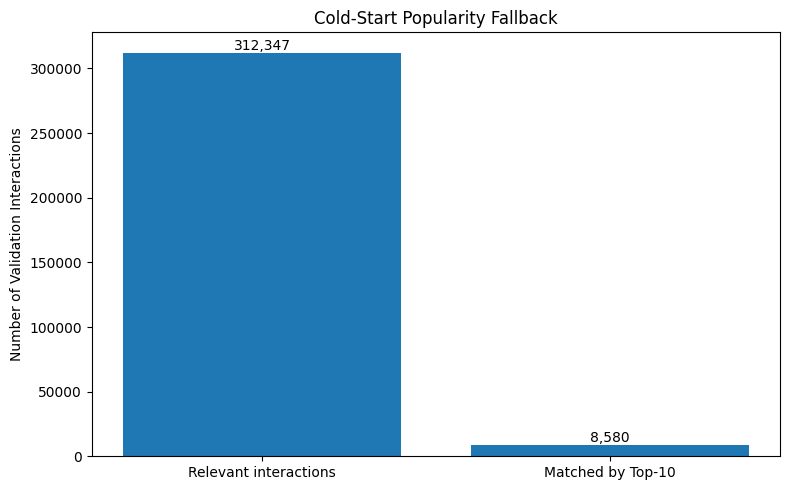

In [ ]:
import matplotlib.pyplot as plt

labels = [
    "Relevant interactions",
    "Matched by Top-10"
]

values = [
    len(relevant_rows),
    int(relevant_rows["hit"].sum())
]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.title("Cold-Start Popularity Fallback")
plt.ylabel("Number of Validation Interactions")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame([
    {
        "Method": "Rating-based Matrix Factorization",
        "Precision@10": 0.0028,
        "Recall@10": 0.0201,
        "NDCG@10": 0.0119
    },
    {
        "Method": "Popularity Baseline (Warm-Start)",
        "Precision@10": 0.0048,
        "Recall@10": 0.0264,
        "NDCG@10": 0.0167
    },
    {
        "Method": "BPR Matrix Factorization",
        "Precision@10": 0.0050,
        "Recall@10": 0.0285,
        "NDCG@10": 0.0168
    }
])

display(results)

print("\nCold-start popularity fallback:")
print(f"Hit Rate@10: {hit_rate_at_10:.4f}")
print(f"Interaction-level Precision@10 estimate: {precision_at_10:.4f}")

,Method,Precision@10,Recall@10,NDCG@10
0,Rating-based Matrix Factorization,0.0028,0.0201,0.0119
1,Popularity Baseline (Warm-Start),0.0048,0.0264,0.0167
2,BPR Matrix Factorization,0.0050,0.0285,0.0168



Cold-start popularity fallback:
Hit Rate@10: 0.0275
Interaction-level Precision@10 estimate: 0.0027


# Results Interpretation

BPR Matrix Factorization achieved the highest scores among the three warm-start ranking methods, with Precision@10 of 0.0050, Recall@10 of 0.0285, and NDCG@10 of 0.0168. However, its improvement over the popularity baseline was small. Rating-based Matrix Factorization performed worse than both methods on the ranking metrics.

The cold-start analysis showed that many users in the validation and test datasets were not present in the training data. Since Matrix Factorization relies on learned user and game representations, it cannot directly provide personalized recommendations for completely unseen users or games. A global popularity fallback can recommend games without user history, but it does not account for individual interests.

These findings motivate combining collaborative filtering with semantic and LLM-based recommendation methods. The performance of the combined system should be evaluated separately using a consistent evaluation procedure.

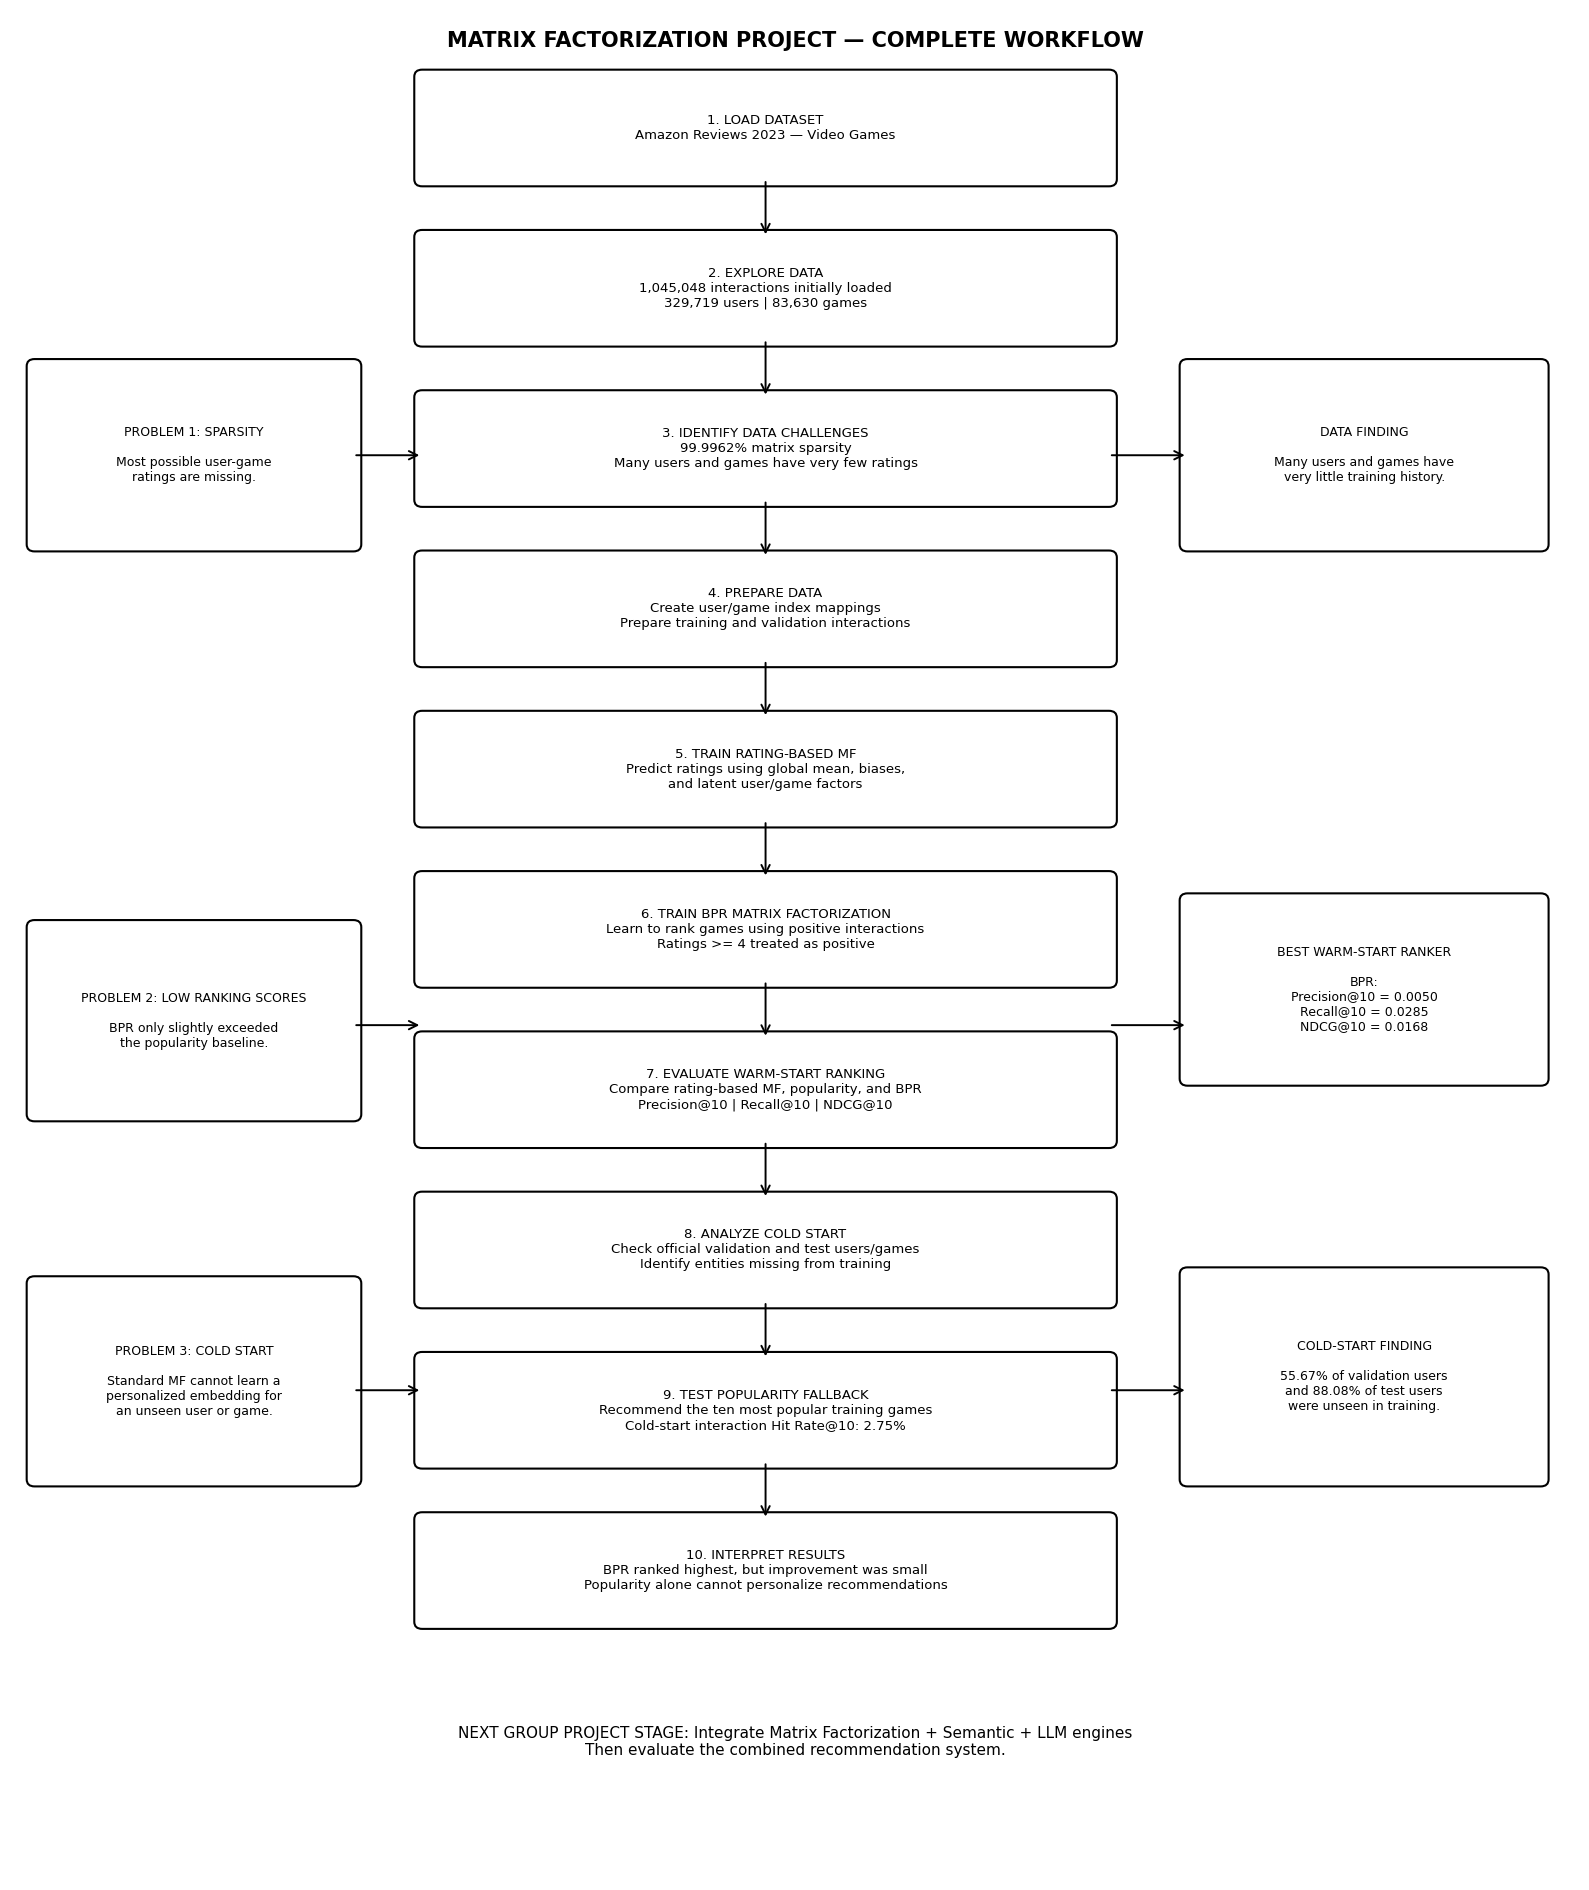

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Create a flowchart without installing additional packages.
fig, ax = plt.subplots(figsize=(16, 19))
ax.set_xlim(0, 16)
ax.set_ylim(0, 21)
ax.axis("off")


def add_box(x, y, width, height, text, fontsize=10, linewidth=1.5):
    """Draw a rounded box and place text inside it."""
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.08",
        linewidth=linewidth,
        fill=False
    )
    ax.add_patch(box)
    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        wrap=True
    )


def add_arrow(x1, y1, x2, y2):
    """Draw an arrow between workflow stages."""
    arrow = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle="->",
        mutation_scale=15,
        linewidth=1.4
    )
    ax.add_patch(arrow)


# Main workflow
main_x = 4.2
main_w = 7.0
box_h = 1.15

stages = [
    (19.1, "1. LOAD DATASET\nAmazon Reviews 2023 — Video Games"),
    (17.3, "2. EXPLORE DATA\n1,045,048 interactions initially loaded\n329,719 users | 83,630 games"),
    (15.5, "3. IDENTIFY DATA CHALLENGES\n99.9962% matrix sparsity\nMany users and games have very few ratings"),
    (13.7, "4. PREPARE DATA\nCreate user/game index mappings\nPrepare training and validation interactions"),
    (11.9, "5. TRAIN RATING-BASED MF\nPredict ratings using global mean, biases,\nand latent user/game factors"),
    (10.1, "6. TRAIN BPR MATRIX FACTORIZATION\nLearn to rank games using positive interactions\nRatings >= 4 treated as positive"),
    (8.3, "7. EVALUATE WARM-START RANKING\nCompare rating-based MF, popularity, and BPR\nPrecision@10 | Recall@10 | NDCG@10"),
    (6.5, "8. ANALYZE COLD START\nCheck official validation and test users/games\nIdentify entities missing from training"),
    (4.7, "9. TEST POPULARITY FALLBACK\nRecommend the ten most popular training games\nCold-start interaction Hit Rate@10: 2.75%"),
    (2.9, "10. INTERPRET RESULTS\nBPR ranked highest, but improvement was small\nPopularity alone cannot personalize recommendations"),
]

for y, label in stages:
    add_box(main_x, y, main_w, box_h, label, fontsize=9.5)

# Arrows between stages
for i in range(len(stages) - 1):
    y_current = stages[i][0]
    y_next = stages[i + 1][0]
    add_arrow(
        main_x + main_w / 2,
        y_current,
        main_x + main_w / 2,
        y_next + box_h
    )

# Left-side problem boxes
add_box(
    0.25, 15.0, 3.25, 2.0,
    "PROBLEM 1: SPARSITY\n\nMost possible user-game\nratings are missing.",
    fontsize=9
)

add_box(
    0.25, 8.6, 3.25, 2.1,
    "PROBLEM 2: LOW RANKING SCORES\n\nBPR only slightly exceeded\nthe popularity baseline.",
    fontsize=9
)

add_box(
    0.25, 4.5, 3.25, 2.2,
    "PROBLEM 3: COLD START\n\nStandard MF cannot learn a\npersonalized embedding for\nan unseen user or game.",
    fontsize=9
)

# Right-side findings
add_box(
    12.0, 15.0, 3.6, 2.0,
    "DATA FINDING\n\nMany users and games have\nvery little training history.",
    fontsize=9
)

add_box(
    12.0, 9.0, 3.6, 2.0,
    "BEST WARM-START RANKER\n\nBPR:\nPrecision@10 = 0.0050\nRecall@10 = 0.0285\nNDCG@10 = 0.0168",
    fontsize=9
)

add_box(
    12.0, 4.5, 3.6, 2.3,
    "COLD-START FINDING\n\n55.67% of validation users\nand 88.08% of test users\nwere unseen in training.",
    fontsize=9
)

# Connect side observations to related workflow stages
add_arrow(3.5, 16.0, main_x, 16.0)
add_arrow(3.5, 9.6, main_x, 9.6)
add_arrow(3.5, 5.5, main_x, 5.5)

add_arrow(main_x + main_w, 16.0, 12.0, 16.0)
add_arrow(main_x + main_w, 9.6, 12.0, 9.6)
add_arrow(main_x + main_w, 5.5, 12.0, 5.5)

ax.text(
    8, 20.65,
    "MATRIX FACTORIZATION PROJECT — COMPLETE WORKFLOW",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

ax.text(
    8, 1.55,
    "NEXT GROUP PROJECT STAGE: Integrate Matrix Factorization + Semantic + LLM engines\n"
    "Then evaluate the combined recommendation system.",
    ha="center",
    va="center",
    fontsize=11
)

plt.tight_layout()
plt.show()

| Problem | What we observed | Why it matters | What we did |
|---|---|---|---|
| **1. Extremely sparse data** | Matrix sparsity was 99.9962%. | There is very little information for many user-game pairs. | Analysed interaction counts and trained collaborative filtering models. |
| **2. Overfitting in rating prediction** | Training RMSE decreased, but validation RMSE eventually worsened. | The model learned the training data without improving its predictions on unseen interactions. | Tested regularization and early stopping. |
| **3. Weak ranking performance** | BPR only slightly outperformed popularity. | Learning user preferences did not produce a substantial improvement in the tested ranking metrics. | Compared all methods using Precision@10, Recall@10, and NDCG@10. |
| **4. Cold-start users** | 55.67% of validation users and 88.08% of test users were absent from training. | Standard MF has no learned user embedding for these users. | Tested a popularity-based fallback. |
| **5. Cold-start games** | 25.68% of validation games and 40.89% of test games were absent from training. | Standard MF has no learned item embedding for these games. | Identified this as a limitation that needs another recommendation approach or a fallback. |
| **6. Limited evaluation sample** | Warm-start ranking was evaluated on 500 sampled users. | Results may not represent performance for the entire user population. | Used a reproducible sample, but a broader evaluation would be useful. |

What We Did — Matrix Factorization
- Loaded the Amazon Reviews 2023 – Video Games dataset.
- Analysed 1.045 million interactions, 329,719 users, and 83,630 games.
- Identified 99.9962% data sparsity.
- Prepared the training and validation datasets.
- Built a Matrix Factorization model to predict user ratings.
- Implemented a popularity-based recommendation baseline.
- Developed BPR Matrix Factorization to rank games based on positive ratings.
- Compared models using Precision@10, Recall@10, and NDCG@10.
- Found that BPR performed best, but only slightly better than popularity.
- Analysed the cold-start problem for unseen users and games.
- Implemented a Top-10 popularity fallback for unseen users.
- Achieved a 2.75% interaction-level Hit Rate@10 for the cold-start fallback.
- Identified cold start and extreme data sparsity as the major challenges.
- Proposed integrating Matrix Factorization with Semantic and LLM-based recommendation engines.

Final outcome: Developed and evaluated the Matrix Factorization component; integration into the complete hybrid recommendation system remains to be done.

In [ ]:
# Inspect variables currently available in Colab

print("=== DATAFRAMES ===")

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(f"{name}: shape={value.shape}")
        print(f"    columns={value.columns.tolist()}")

print("\n=== BPR MODEL ===")

for name, value in list(globals().items()):
    if isinstance(value, torch.nn.Module):
        print(f"{name}: {type(value).__name__}")

print("\n=== USER/GAME MAPPINGS ===")

for name in [
    "user_to_idx",
    "idx_to_game",
    "game_to_idx",
    "item_to_idx",
    "user_to_index",
    "game_to_index"
]:
    if name in globals():
        value = globals()[name]
        try:
            print(f"{name}: {len(value)} entries")
        except TypeError:
            print(f"{name}: exists")

print("\n=== POSSIBLE TRAINING VARIABLES ===")

for name in list(globals().keys()):
    if any(word in name.lower() for word in ["train", "interact", "rating", "dataset"]):
        print(name)

=== DATAFRAMES ===

=== BPR MODEL ===

=== USER/GAME MAPPINGS ===

=== POSSIBLE TRAINING VARIABLES ===
find_training_dataframe


In [ ]:
import pandas as pd
import numpy as np
import torch

DATA_BASE = (
    "https://huggingface.co/datasets/McAuley-Lab/"
    "Amazon-Reviews-2023/resolve/main/"
    "benchmark/0core/last_out"
)

train_df = pd.read_csv(
    f"{DATA_BASE}/Video_Games.train.csv"
)

print("Training dataset loaded:", train_df.shape)
display(train_df.head())

Training dataset loaded: (1045048, 4)


,user_id,parent_asin,rating,timestamp
0,AG6BAEKWLCWH2TW3KKLVK773YF6A,B0B36HX334,1.0,1523313903402
1,AG6BAEKWLCWH2TW3KKLVK773YF6A,B001AW156U,4.0,1523314072900
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1611459666223
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1613701986538
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1613702112995


In [ ]:
# Step 1: Prepare data for BPR

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

# Use the same random seed for reproducibility
warm_train_raw, warm_valid_raw = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42
)

# BPR learns from positive interactions (rating >= 4)
positive_train = warm_train_raw[
    warm_train_raw["rating"] >= 4
].copy()

# Create mappings
user_ids = positive_train["user_id"].unique()
game_ids = warm_train_raw["parent_asin"].unique()

user_to_idx = {user_id: i for i, user_id in enumerate(user_ids)}
game_to_idx = {game_id: i for i, game_id in enumerate(game_ids)}

idx_to_user = {i: user_id for user_id, i in user_to_idx.items()}
idx_to_game = {i: game_id for game_id, i in game_to_idx.items()}

# Convert positive interactions into integer indices
positive_train["user_idx"] = positive_train["user_id"].map(user_to_idx)
positive_train["game_idx"] = positive_train["parent_asin"].map(game_to_idx)

# Build each user's positive-game history
user_positive_games = (
    positive_train.groupby("user_idx")["game_idx"]
    .apply(set)
    .to_dict()
)

print("Preparation complete!")
print("Training interactions:", len(warm_train_raw))
print("Positive interactions:", len(positive_train))
print("Users with positive interactions:", len(user_to_idx))
print("Games in catalogue:", len(game_to_idx))
print("Validation interactions:", len(warm_valid_raw))
print("PyTorch device:", "GPU" if torch.cuda.is_available() else "CPU")

Preparation complete!
Training interactions: 836038
Positive interactions: 664591
Users with positive interactions: 257848
Games in catalogue: 76997
Validation interactions: 209010
PyTorch device: CPU


In [ ]:
# Step 2: Build and train the BPR model

import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# BPR model
class BPRMatrixFactorization(nn.Module):
    def __init__(self, n_users, n_games, n_factors=32):
        super().__init__()

        self.user_embedding = nn.Embedding(n_users, n_factors)
        self.game_embedding = nn.Embedding(n_games, n_factors)

        nn.init.normal_(self.user_embedding.weight, std=0.1)
        nn.init.normal_(self.game_embedding.weight, std=0.1)

    def forward(self, users, positive_games, negative_games):
        user_vec = self.user_embedding(users)
        positive_vec = self.game_embedding(positive_games)
        negative_vec = self.game_embedding(negative_games)

        positive_scores = (user_vec * positive_vec).sum(dim=1)
        negative_scores = (user_vec * negative_vec).sum(dim=1)

        return positive_scores, negative_scores


# Convert positive interactions to arrays
positive_users = positive_train["user_idx"].to_numpy(dtype=np.int64)
positive_games = positive_train["game_idx"].to_numpy(dtype=np.int64)

# Each user gets a set of games they positively rated
all_game_indices = np.arange(len(game_to_idx))

# Dataset creates a negative sample for each positive interaction
class BPRDataset(Dataset):
    def __init__(self, users, games, user_history, n_games):
        self.users = users
        self.games = games
        self.user_history = user_history
        self.n_games = n_games

    def __len__(self):
        return len(self.users)

    def __getitem__(self, index):
        user = int(self.users[index])
        positive_game = int(self.games[index])

        # Sample a game the user has not positively rated
        negative_game = np.random.randint(self.n_games)
        attempts = 0

        while negative_game in self.user_history[user] and attempts < 50:
            negative_game = np.random.randint(self.n_games)
            attempts += 1

        return user, positive_game, negative_game


train_dataset = BPRDataset(
    positive_users,
    positive_games,
    user_positive_games,
    len(game_to_idx)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4096,
    shuffle=True,
    num_workers=0
)

bpr_model = BPRMatrixFactorization(
    n_users=len(user_to_idx),
    n_games=len(game_to_idx),
    n_factors=32
).to(device)

optimizer = torch.optim.Adam(bpr_model.parameters(), lr=0.001)

EPOCHS = 5
REG = 1e-5

print("Starting BPR training on:", device)

for epoch in range(EPOCHS):
    bpr_model.train()
    total_loss = 0.0
    total_examples = 0

    for users, pos_games, neg_games in train_loader:
        users = users.to(device)
        pos_games = pos_games.to(device)
        neg_games = neg_games.to(device)

        optimizer.zero_grad()

        pos_scores, neg_scores = bpr_model(
            users, pos_games, neg_games
        )

        # BPR ranking loss
        ranking_loss = -F.logsigmoid(
            pos_scores - neg_scores
        ).mean()

        # L2 regularization
        user_vec = bpr_model.user_embedding(users)
        pos_vec = bpr_model.game_embedding(pos_games)
        neg_vec = bpr_model.game_embedding(neg_games)

        regularization = (
            user_vec.pow(2).sum(dim=1).mean()
            + pos_vec.pow(2).sum(dim=1).mean()
            + neg_vec.pow(2).sum(dim=1).mean()
        )

        loss = ranking_loss + REG * regularization
        loss.backward()
        optimizer.step()

        batch_size = users.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

    average_loss = total_loss / total_examples
    print(f"Epoch {epoch + 1}/{EPOCHS} | BPR loss: {average_loss:.4f}")

print("\nBPR training complete!")
print("Users:", bpr_model.user_embedding.num_embeddings)
print("Games:", bpr_model.game_embedding.num_embeddings)
print("Latent factors:", bpr_model.user_embedding.embedding_dim)

Starting BPR training on: cpu
Epoch 1/5 | BPR loss: 0.6940
Epoch 2/5 | BPR loss: 0.6852
Epoch 3/5 | BPR loss: 0.6747
Epoch 4/5 | BPR loss: 0.6616
Epoch 5/5 | BPR loss: 0.6441

BPR training complete!
Users: 257848
Games: 76997
Latent factors: 32


In [ ]:
import os
import torch

SAVE_DIR = "/content/drive/MyDrive/Video_Game_Recommender"
os.makedirs(SAVE_DIR, exist_ok=True)

MODEL_PATH = os.path.join(SAVE_DIR, "best_bpr_model.pth")

checkpoint = {
    "model_state_dict": bpr_model.state_dict(),
    "user_to_idx": user_to_idx,
    "game_to_idx": game_to_idx,
    "idx_to_game": idx_to_game,
    "idx_to_user": idx_to_user,
}

torch.save(checkpoint, MODEL_PATH)

print("BPR model saved successfully!")
print("Saved location:", MODEL_PATH)

BPR model saved successfully!
Saved location: /content/drive/MyDrive/Video_Game_Recommender/best_bpr_model.pth


In [ ]:
# Step 3: Create the recommendation engine

from collections import Counter

# Games each user has already interacted with
user_seen_games = (
    warm_train_raw.groupby("user_id")["parent_asin"]
    .apply(set)
    .to_dict()
)

# Popular games based on positive ratings in the training data
popular_games = (
    positive_train.groupby("parent_asin")
    .size()
    .sort_values(ascending=False)
    .index
    .tolist()
)

def recommend_games(user_id, top_n=10):
    user_id = str(user_id).strip()

    # Unknown users receive popular-game recommendations
    if user_id not in user_to_idx:
        recommendations = [
            game for game in popular_games
            if game not in user_seen_games.get(user_id, set())
        ][:top_n]

        return pd.DataFrame({
            "Rank": range(1, len(recommendations) + 1),
            "Game ID": recommendations,
            "Recommendation Type": ["Popular games"] * len(recommendations)
        })

    # Get the user's BPR scores for every game
    bpr_model.eval()

    with torch.no_grad():
        user_idx = user_to_idx[user_id]
        user_tensor = torch.tensor([user_idx], dtype=torch.long, device=device)

        user_vector = bpr_model.user_embedding(user_tensor)
        game_vectors = bpr_model.game_embedding.weight

        scores = (user_vector @ game_vectors.T).squeeze(0).cpu().numpy()

    # Rank games by predicted preference
    ranked_indices = np.argsort(scores)[::-1]

    seen = user_seen_games.get(user_id, set())
    recommendations = []

    for game_idx in ranked_indices:
        game_id = idx_to_game[int(game_idx)]

        if game_id not in seen:
            recommendations.append((game_id, float(scores[game_idx])))

        if len(recommendations) >= top_n:
            break

    return pd.DataFrame({
        "Rank": range(1, len(recommendations) + 1),
        "Game ID": [game for game, score in recommendations],
        "BPR Score": [round(score, 4) for game, score in recommendations],
        "Recommendation Type": ["Personalized BPR"] * len(recommendations)
    })


print("Recommendation engine is ready!")

Recommendation engine is ready!


In [ ]:
# Step 4: Test recommendations

sample_user_id = positive_train["user_id"].iloc[0]

print("Sample user:", sample_user_id)
display(recommend_games(sample_user_id, top_n=10))

Sample user: AHIVNDHT7JI62AKC2YJWMOHCDVRA


,Rank,Game ID,BPR Score,Recommendation Type
0,1,B00CJ9OTNE,0.4391,Personalized BPR
1,2,B07PZ8NZSZ,0.3742,Personalized BPR
2,3,B08F4D36D9,0.3311,Personalized BPR
3,4,B07MPNY1YS,0.3272,Personalized BPR
4,5,B07G4YYZ1M,0.3076,Personalized BPR
5,6,B00005O0I2,0.3040,Personalized BPR
6,7,B001ELJF6Y,0.3026,Personalized BPR
7,8,B07447J2TS,0.3005,Personalized BPR
8,9,B00000DMB3,0.2967,Personalized BPR
9,10,B095CDXD2R,0.2903,Personalized BPR


In [ ]:
# Step 5: Build the Gradio interface

%pip -q install gradio

import gradio as gr
import pandas as pd

def recommendation_interface(user_id):
    if not user_id or not user_id.strip():
        return pd.DataFrame(columns=[
            "Rank", "Game ID", "BPR Score", "Recommendation Type"
        ]), "Please enter an Amazon user ID."

    try:
        results = recommend_games(user_id.strip(), top_n=10)

        if results.empty:
            return results, "No recommendations were found."

        rec_type = results["Recommendation Type"].iloc[0]

        if rec_type == "Personalized BPR":
            message = "Personalized recommendations generated using the trained BPR model."
        else:
            message = (
                "This user is not recognized by the BPR model. "
                "Showing popular games instead."
            )

        return results, message

    except Exception as e:
        return pd.DataFrame(), f"Error: {str(e)}"


with gr.Blocks(title="Video Game Recommendation System") as demo:
    gr.Markdown("# Video Game Recommendation System")
    gr.Markdown(
        "Enter an Amazon user ID to receive game recommendations. "
        "Known users receive personalized recommendations; new users receive popular games."
    )

    user_input = gr.Textbox(
        label="Amazon User ID",
        placeholder="Example: AHIVNDHT7JI62AKC2YJWMOHCDVRA"
    )

    recommend_button = gr.Button("Recommend Games", variant="primary")

    output_table = gr.Dataframe(
        label="Recommended Games",
        interactive=False
    )

    status_message = gr.Textbox(
        label="Status",
        interactive=False
    )

    recommend_button.click(
        fn=recommendation_interface,
        inputs=user_input,
        outputs=[output_table, status_message]
    )

    user_input.submit(
        fn=recommendation_interface,
        inputs=user_input,
        outputs=[output_table, status_message]
    )

demo.launch(share=False, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

Keyboard interruption in main thread... closing server.


In [ ]:
# Download and load the correct Video Games metadata

import os
import requests
import pandas as pd

META_FILE = "/content/video_games_metadata.parquet"

META_URL = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/resolve/"
    "fb22017ccfb88805edb9d974689e5ead97c608d1/"
    "raw_meta_Video_Games/full-00000-of-00001.parquet"
)

if not os.path.exists(META_FILE):
    print("Downloading metadata (approximately 154 MB)...")

    response = requests.get(META_URL, stream=True, timeout=120)
    response.raise_for_status()

    with open(META_FILE, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print("Download complete!")

metadata_df = pd.read_parquet(META_FILE)

print("Metadata loaded:", metadata_df.shape)
print("Columns:", metadata_df.columns.tolist())

display(metadata_df[["parent_asin", "title"]].head())

Download complete!
Metadata loaded: (137269, 16)
Columns: ['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author']


,parent_asin,title
0,B000FH0MHO,Dash 8-300 Professional Add-On
1,B00069EVOG,Phantasmagoria: A Puzzle of Flesh
2,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4
3,B07SZJZV88,Nintendo Selects: The Legend of Zelda Ocarina ...
4,B002WH4ZJG,Thrustmaster Elite Fitness Pack for Nintendo Wii


In [ ]:
# FIX: Prepare the game catalogue safely
import pandas as pd
import numpy as np

print("Preparing game catalogue...")

# Use the metadata already downloaded
catalogue = metadata_df.copy()

catalogue["parent_asin"] = catalogue["parent_asin"].astype(str)

# Keep only games known to the BPR model
valid_game_ids = set(str(game_id) for game_id in game_to_idx.keys())

catalogue = catalogue[
    catalogue["parent_asin"].isin(valid_game_ids)
].copy()

# Metadata columns available for searching
metadata_fields = [
    col for col in [
        "title",
        "description",
        "features",
        "categories",
        "details"
    ]
    if col in catalogue.columns
]


# Convert any metadata value into safe text
def safe_text(value):

    if value is None:
        return ""

    if isinstance(value, np.ndarray):
        value = value.tolist()

    if isinstance(value, (list, tuple, set)):
        return " ".join(safe_text(item) for item in value)

    if isinstance(value, dict):
        return " ".join(
            safe_text(key) + " " + safe_text(val)
            for key, val in value.items()
        )

    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return ""

    if isinstance(value, (int, float, np.integer, np.bool_)):
        return str(value)

    if isinstance(value, str):
        return value

    try:
        if pd.isna(value):
            return ""
    except (ValueError, TypeError):
        pass

    return str(value)


# Build searchable text for each game
catalogue["search_text"] = catalogue.apply(
    lambda row: " ".join(
        safe_text(row[field])
        for field in metadata_fields
    ).lower(),
    axis=1
)

# Build game ID -> title lookup
title_lookup = {}

for _, row in catalogue.iterrows():
    game_id = str(row["parent_asin"])
    title = safe_text(row.get("title", "")).strip()

    title_lookup[game_id] = title if title else "Untitled Game"

print("Catalogue preparation successful!")
print("Games in BPR catalogue:", len(game_to_idx))
print("Games matched with metadata:", len(catalogue))
print("Searchable fields:", metadata_fields)

display(catalogue[["parent_asin", "title", "search_text"]].head(5))

Preparing game catalogue...
Catalogue preparation successful!
Games in BPR catalogue: 76997
Games matched with metadata: 76997
Searchable fields: ['title', 'description', 'features', 'categories', 'details']


,parent_asin,title,search_text
1,B00069EVOG,Phantasmagoria: A Puzzle of Flesh,phantasmagoria: a puzzle of flesh windows 95 ...
2,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,nba 2k17 - early tip off edition - playstation...
3,B07SZJZV88,Nintendo Selects: The Legend of Zelda Ocarina ...,nintendo selects: the legend of zelda ocarina ...
5,B00005Y3OJ,Grand Prix 4,grand prix 4 grand prix 4 is the fourth instal...
6,B0001ZNU56,"Spongebob Squarepants, Vol. 1","spongebob squarepants, vol. 1 now you can watc..."


In [ ]:
# ============================================================
# VIDEO GAME RECOMMENDER SYSTEM - GRADIO INTERFACE
# ============================================================

%pip -q install gradio

import gradio as gr
import pandas as pd
import numpy as np
import torch
import re

# ------------------------------------------------------------
# 1. POPULARITY FALLBACK
# ------------------------------------------------------------

popular_games = (
    positive_train.groupby("parent_asin")
    .size()
    .sort_values(ascending=False)
    .index.astype(str)
    .tolist()
)

# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def split_preferences(text):
    if not text:
        return []

    return [
        item.strip().lower()
        for item in re.split(r"[,;\n]", str(text))
        if item.strip()
    ]


def get_title(game_id):
    return title_lookup.get(str(game_id), "Untitled Game")


def make_results(game_ids, scores, method):
    rows = []

    for rank, (game_id, score) in enumerate(
        zip(game_ids, scores), start=1
    ):
        rows.append({
            "Rank": rank,
            "Game Title": get_title(game_id),
            "Game ID": str(game_id),
            "Score": round(float(score), 4),
            "Method": method
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 3. EXISTING USER: BPR RECOMMENDATIONS
# ------------------------------------------------------------

def recommend_existing_user(user_id, top_n=10):

    user_index = user_to_idx[user_id]

    bpr_model.eval()

    with torch.no_grad():

        user_tensor = torch.tensor(
            [user_index],
            dtype=torch.long,
            device=device
        )

        user_vector = bpr_model.user_embedding(user_tensor)

        game_vectors = bpr_model.game_embedding.weight

        scores = (
            user_vector @ game_vectors.T
        ).squeeze(0).cpu().numpy()

    seen = user_seen_games.get(user_id, set())

    for game_id in seen:
        if game_id in game_to_idx:
            scores[game_to_idx[game_id]] = -np.inf

    ranked_indices = np.argsort(scores)[::-1]

    game_ids = []
    game_scores = []

    for idx in ranked_indices:

        if not np.isfinite(scores[idx]):
            continue

        game_id = str(idx_to_game[idx])

        game_ids.append(game_id)
        game_scores.append(float(scores[idx]))

        if len(game_ids) == top_n:
            break

    return make_results(
        game_ids,
        game_scores,
        "BPR Collaborative Filtering"
    )


# ------------------------------------------------------------
# 4. NEW USER: METADATA MATCHING
# ------------------------------------------------------------

def recommend_new_user(
    genres,
    favourite_games,
    platforms,
    top_n=10
):

    genres = split_preferences(genres)
    favourite_games = split_preferences(favourite_games)
    platforms = split_preferences(platforms)

    # Score each game against the user's preferences
    scored_games = []

    for _, row in catalogue.iterrows():

        game_id = str(row["parent_asin"])
        searchable_text = row["search_text"]
        title = get_title(game_id).lower()

        score = 0

        # Genre preferences
        for genre in genres:
            if genre in searchable_text:
                score += 3

        # Favourite games
        for game in favourite_games:
            if game in title:
                score += 5
            elif game in searchable_text:
                score += 2

        # Preferred platforms
        for platform in platforms:
            if platform in searchable_text:
                score += 2

        if score > 0:
            scored_games.append((game_id, score))

    # Rank by preference score
    scored_games.sort(
        key=lambda item: item[1],
        reverse=True
    )

    selected = []
    selected_ids = set()

    for game_id, score in scored_games:

        if game_id not in selected_ids:
            selected.append((game_id, score))
            selected_ids.add(game_id)

        if len(selected) >= top_n:
            break

    # Fill any remaining slots with popular games
    if len(selected) < top_n:

        for game_id in popular_games:

            game_id = str(game_id)

            if (
                game_id in game_to_idx
                and game_id not in selected_ids
            ):
                selected.append((game_id, 0))
                selected_ids.add(game_id)

            if len(selected) >= top_n:
                break

    game_ids = [item[0] for item in selected]
    scores = [item[1] for item in selected]

    method = (
        "Metadata Cold-Start Matching"
        if scored_games
        else "Popularity Fallback"
    )

    return make_results(game_ids, scores, method)


# ------------------------------------------------------------
# 5. MAIN FUNCTION
# ------------------------------------------------------------

def run_recommender(
    name,
    user_id,
    genres,
    favourite_games,
    platforms
):

    name = str(name).strip() if name else "User"
    user_id = str(user_id).strip() if user_id else ""

    # Use BPR for a recognized existing user
    if user_id in user_to_idx:

        results = recommend_existing_user(user_id)

        if results.empty:
            return (
                f"No unseen recommendations found for {name}.",
                results
            )

        return (
            f"Recommendations for {name} — BPR model",
            results
        )

    # Use metadata matching for a new user
    results = recommend_new_user(
        genres,
        favourite_games,
        platforms
    )

    if user_id:
        message = (
            f"Recommendations for {name} — cold-start mode. "
            "The supplied user ID was not found in the trained model."
        )
    else:
        message = (
            f"Recommendations for {name} — cold-start mode."
        )

    return message, results


# ------------------------------------------------------------
# 6. GRADIO INTERFACE
# ------------------------------------------------------------

with gr.Blocks(
    title="Video Game Recommender System"
) as demo:

    gr.Markdown(
        """
        # 🎮 Video Game Recommender System

        Discover games suited to your interests.

        **Existing user:** Enter your Amazon user ID.

        **New user:** Leave the ID blank and enter your preferences.
        """
    )

    with gr.Row():

        name_input = gr.Textbox(
            label="Name",
            placeholder="e.g. Rahul"
        )

        user_id_input = gr.Textbox(
            label="Existing Amazon User ID (optional)",
            placeholder="Leave blank for a new user"
        )

    genres_input = gr.Textbox(
        label="Favourite Genres",
        placeholder="Action, Racing, Adventure"
    )

    games_input = gr.Textbox(
        label="Favourite Games",
        placeholder="GTA V, Forza Horizon 5"
    )

    platforms_input = gr.Textbox(
        label="Preferred Platforms",
        placeholder="PC, PlayStation, Xbox"
    )

    recommend_button = gr.Button(
        "Get Recommendations",
        variant="primary"
    )

    status_output = gr.Textbox(
        label="Status",
        interactive=False
    )

    results_output = gr.Dataframe(
        label="Recommended Games",
        interactive=False
    )

    recommend_button.click(
        fn=run_recommender,
        inputs=[
            name_input,
            user_id_input,
            genres_input,
            games_input,
            platforms_input
        ],
        outputs=[
            status_output,
            results_output
        ]
    )

print("Launching the recommender interface...")

demo.launch(
    share=False,
    debug=True
)

NameError: name 'positive_train' is not defined